# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

# Automated

In [200]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [201]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0
rrs_id = 999999.0

In [202]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [203]:
scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control'] == True]
scores = scores[scores['media_control'] == False]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores_before_seq = scores.clone()

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,false,8.982013,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A04""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,544.3046,false,9.215059,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,false,9.118748,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A06""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,536.567345,false,9.196153,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",4.0,498.666689,false,9.099786,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P18""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,53212.0,null,54308.0,218853.0,"""VUSMutY8Dh022""","""G09""","""CEGSint_Y8A_7""","""F04""",2.0,412.423535,false,8.853071,178.228434,"""ROPN1""","""PKP2""","""Ala372Pro""","""1114G>C""","""ENSG00000057294""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""PKP2_Ala372Pro""","""54308.0_218853.0""","""54308.0_218853.0_LWAH1_VUSAPWT…","""53212.0_54308.0_218853.0_VUSAP…","""53212.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218854.0,"""VUSMutY8Dh022""","""H09""","""CEGSint_Y8A_6""","""E11""",2.0,659.198706,false,9.470046,null,"""SPTA1""","""PKP2""","""Phe424Ser""","""1271T>C""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Phe424Ser""","""54308.0_218854.0""","""54308.0_218854.0_LWAH1_VUSAPWT…","""100069191.0_54308.0_218854.0_V…","""100069191.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P20""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B

In [204]:
def get_filtering_stats(scores_df, aa_id, rrs_id, step_name=""):
    """
    Get filtering statistics for a scores dataframe and return as dictionary
    
    Parameters:
    scores_df: polars DataFrame with the scores data
    aa_id: autoactivation ID to exclude 
    rrs_id: RRS ID to exclude
    step_name: optional name for the filtering step
    
    Returns:
    dict: Dictionary containing various counts
    """
    
    # Filter for non-autoactivation, non-RRS entries
    filtered_scores = scores_df.filter(
        (pl.col("ad_orf_id") != aa_id) & 
        (pl.col("db_mut_id") != rrs_id)
    )
    
    stats = {
        'step_name': step_name,
        'total_rows': scores_df.shape[0],
        'ppi_groups': filtered_scores.select(pl.col("ppi_group").n_unique()).item(),
        'db_orf_ids': filtered_scores.select(pl.col("db_orf_id").n_unique()).item(),
        'ad_orf_ids': filtered_scores.select(pl.col("ad_orf_id").n_unique()).item(),
        'db_groups': filtered_scores.select(pl.col("db_group").n_unique()).item(),
        'edge_groups': filtered_scores.select(pl.col("edge_group").n_unique()).item()
    }
    
    # Add counts for db_orf_ids with both WT and variants
    try:
        # Find db_orf_ids with WT data
        db_orfs_with_wt = filtered_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique()
        
        # Find db_orf_ids with variant data  
        db_orfs_with_variants = filtered_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique()
        
        # Get intersection - db_orf_ids that have both WT and variants
        db_orfs_with_both = db_orfs_with_wt.join(
            db_orfs_with_variants, 
            on="db_orf_id", 
            how="inner"
        )
        
        stats['db_orfs_with_wt'] = db_orfs_with_wt.height
        stats['db_orfs_with_variants'] = db_orfs_with_variants.height  
        stats['db_orfs_with_both_wt_and_variants'] = db_orfs_with_both.height
        
        # Filter to only include db_orf_ids that have both WT and variants
        scores_both = scores_df.filter(pl.col("db_orf_id").is_in(db_orfs_with_both.select("db_orf_id").to_series().to_list()))
        filtered_scores_both = scores_both.filter(
            (pl.col("ad_orf_id") != aa_id) & 
            (pl.col("db_mut_id") != rrs_id)
        )
        
        # Get ALL the statistics for the WT+variant filtered dataset
        stats['ppi_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ppi_group").n_unique()).item()
        stats['db_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_orf_id").n_unique()).item()
        stats['ad_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ad_orf_id").n_unique()).item()
        stats['db_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_group").n_unique()).item()
        stats['edge_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("edge_group").n_unique()).item()
        
    except Exception as e:
        print(f"Warning: Could not calculate WT/variant stats for {step_name}: {e}")
        stats['db_orfs_with_wt'] = None
        stats['db_orfs_with_variants'] = None
        stats['db_orfs_with_both_wt_and_variants'] = None
        stats['ppi_groups_with_both_wt_variants'] = None
        stats['db_orf_ids_with_both_wt_variants'] = None
        stats['ad_orf_ids_with_both_wt_variants'] = None
        stats['db_groups_with_both_wt_variants'] = None
        stats['edge_groups_with_both_wt_variants'] = None
    
    return stats

def create_comprehensive_filtering_table(filtering_stats_list):
    """
    Create a comprehensive table showing all filtering steps with counts and percentages
    """
    import pandas as pd
    
    # Initialize the summary table
    summary_data = []
    
    for i, stats in enumerate(filtering_stats_list):
        if i == 0:
            # First step - no previous comparison
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': 0,
                'PPIs_Dropped': 0,
                'DB_ORFs_Dropped': 0,
                'AD_ORFs_Dropped': 0,
                'DB_Groups_Dropped': 0,
                'Edge_Groups_Dropped': 0,
                'DB_ORFs_Both_Dropped': 0,
                'PPI_Groups_Both_Dropped': 0,
                'DB_ORF_IDs_Both_Dropped': 0,
                'AD_ORF_IDs_Both_Dropped': 0,
                'DB_Groups_Both_Dropped': 0,
                'Edge_Groups_Both_Dropped': 0,
                'Percent_Rows_Dropped': 0.0,
                'Percent_PPIs_Dropped': 0.0,
                'Percent_DB_ORFs_Dropped': 0.0,
                'Percent_AD_ORFs_Dropped': 0.0,
                'Percent_DB_Groups_Dropped': 0.0,
                'Percent_Edge_Groups_Dropped': 0.0,
                'Percent_DB_ORFs_Both_Dropped': 0.0,
                'Percent_PPI_Groups_Both_Dropped': 0.0,
                'Percent_DB_ORF_IDs_Both_Dropped': 0.0,
                'Percent_AD_ORF_IDs_Both_Dropped': 0.0,
                'Percent_DB_Groups_Both_Dropped': 0.0,
                'Percent_Edge_Groups_Both_Dropped': 0.0
            }
        else:
            # Compare with previous step
            prev_stats = filtering_stats_list[i-1]
            
            rows_dropped = prev_stats['total_rows'] - stats['total_rows']
            ppis_dropped = prev_stats['ppi_groups'] - stats['ppi_groups']
            db_orfs_dropped = prev_stats['db_orf_ids'] - stats['db_orf_ids']
            ad_orfs_dropped = prev_stats['ad_orf_ids'] - stats['ad_orf_ids']
            db_groups_dropped = prev_stats['db_groups'] - stats['db_groups']
            edge_groups_dropped = prev_stats['edge_groups'] - stats['edge_groups']
            
            # Handle WT/variant specific drops for ALL metrics
            db_orfs_both_dropped = 0
            ppi_groups_both_dropped = 0
            db_orf_ids_both_dropped = 0
            ad_orf_ids_both_dropped = 0
            db_groups_both_dropped = 0
            edge_groups_both_dropped = 0
            
            if (prev_stats.get('db_orfs_with_both_wt_and_variants') is not None and 
                stats.get('db_orfs_with_both_wt_and_variants') is not None):
                db_orfs_both_dropped = prev_stats['db_orfs_with_both_wt_and_variants'] - stats['db_orfs_with_both_wt_and_variants']
                ppi_groups_both_dropped = prev_stats['ppi_groups_with_both_wt_variants'] - stats['ppi_groups_with_both_wt_variants']
                db_orf_ids_both_dropped = prev_stats['db_orf_ids_with_both_wt_variants'] - stats['db_orf_ids_with_both_wt_variants']
                ad_orf_ids_both_dropped = prev_stats['ad_orf_ids_with_both_wt_variants'] - stats['ad_orf_ids_with_both_wt_variants']
                db_groups_both_dropped = prev_stats['db_groups_with_both_wt_variants'] - stats['db_groups_with_both_wt_variants']
                edge_groups_both_dropped = prev_stats['edge_groups_with_both_wt_variants'] - stats['edge_groups_with_both_wt_variants']
            
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': rows_dropped,
                'PPIs_Dropped': ppis_dropped,
                'DB_ORFs_Dropped': db_orfs_dropped,
                'AD_ORFs_Dropped': ad_orfs_dropped,
                'DB_Groups_Dropped': db_groups_dropped,
                'Edge_Groups_Dropped': edge_groups_dropped,
                'DB_ORFs_Both_Dropped': db_orfs_both_dropped,
                'PPI_Groups_Both_Dropped': ppi_groups_both_dropped,
                'DB_ORF_IDs_Both_Dropped': db_orf_ids_both_dropped,
                'AD_ORF_IDs_Both_Dropped': ad_orf_ids_both_dropped,
                'DB_Groups_Both_Dropped': db_groups_both_dropped,
                'Edge_Groups_Both_Dropped': edge_groups_both_dropped,
                'Percent_Rows_Dropped': round((rows_dropped / prev_stats['total_rows']) * 100, 2) if prev_stats['total_rows'] > 0 else 0,
                'Percent_PPIs_Dropped': round((ppis_dropped / prev_stats['ppi_groups']) * 100, 2) if prev_stats['ppi_groups'] > 0 else 0,
                'Percent_DB_ORFs_Dropped': round((db_orfs_dropped / prev_stats['db_orf_ids']) * 100, 2) if prev_stats['db_orf_ids'] > 0 else 0,
                'Percent_AD_ORFs_Dropped': round((ad_orfs_dropped / prev_stats['ad_orf_ids']) * 100, 2) if prev_stats['ad_orf_ids'] > 0 else 0,
                'Percent_DB_Groups_Dropped': round((db_groups_dropped / prev_stats['db_groups']) * 100, 2) if prev_stats['db_groups'] > 0 else 0,
                'Percent_Edge_Groups_Dropped': round((edge_groups_dropped / prev_stats['edge_groups']) * 100, 2) if prev_stats['edge_groups'] > 0 else 0,
                'Percent_DB_ORFs_Both_Dropped': round((db_orfs_both_dropped / prev_stats['db_orfs_with_both_wt_and_variants']) * 100, 2) if prev_stats.get('db_orfs_with_both_wt_and_variants', 0) > 0 else 0,
                'Percent_PPI_Groups_Both_Dropped': round((ppi_groups_both_dropped / prev_stats['ppi_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('ppi_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_ORF_IDs_Both_Dropped': round((db_orf_ids_both_dropped / prev_stats['db_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_AD_ORF_IDs_Both_Dropped': round((ad_orf_ids_both_dropped / prev_stats['ad_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('ad_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_Groups_Both_Dropped': round((db_groups_both_dropped / prev_stats['db_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_Edge_Groups_Both_Dropped': round((edge_groups_both_dropped / prev_stats['edge_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('edge_groups_with_both_wt_variants', 0) > 0 else 0
            }
        
        summary_data.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(summary_data)
    
    return df

In [205]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])


# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

final_sequencing_df = pd.read_csv(f"{meta_outputs}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)

final_sequencing_df

# Convert final_sequencing_df to polars and ensure matching data types
final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "db_seq_final"])

# Join the db_seq_final column onto scores
scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

print(f"Scores shape: {scores.shape}")
print(f"Unique values in db_seq_final: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")


scores_aa_rrs = scores.filter(
    (pl.col("ad_orf_id") == aa_id) | 
    (pl.col("db_mut_id") == rrs_id)
)

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
    (
        (pl.col("db_mut_id") == 0) |  # WT is always good
        (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
    )
)

scores = pl.concat([scores, scores_aa_rrs])

print("After sequence confirmation filtering:")
print(f"Scores shape: {scores.shape}")
print(f"Unique db_seq_final values: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")

scores
scores_after_seq = scores.clone()

Scores shape: (285965, 38)
Unique values in db_seq_final: [None, 'Y', 'N']
After sequence confirmation filtering:
Scores shape: (193138, 38)
Unique db_seq_final values: [None, 'Y', 'N']


In [206]:
scores_pd = scores.to_pandas()
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,528.001331,False,9.174929,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None
1,VUSAPWT1B1r01_001,A16,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,595.377806,False,9.334000,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None
2,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,585.556892,False,9.311877,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None
3,VUSAPWT1B1r01_001,A18,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,603.194803,False,9.351370,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None
4,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,52920,0,DisWTGDEh03,A05,CEGSint_Y8A_5,A06,4.0,572.135977,False,9.281086,578.211793,TAX1BP1,LITAF,None,None,ENSG00000189067,None,None,NaN,NaN,LITAF,52920.0_0.0,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193133,VUSAPWT1B1r06_036,P06,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,13295,218058,VUSMutY8Dh022,H03,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,1.149346,empty_ad,TTPA,His101Gln,303T>G,ENSG00000137561,CEGS2,1_Pathogenic,NaN,2.0,TTPA_His101Gln,13295.0_218058.0,13295.0_218058.0_LWAH1_VUSAPWT1B1,0.0_13295.0_218058.0_VUSAPWT1B1,0.0_13295.0_VUSAPWT1B1,None,0,Y
193134,VUSAPWT1B1r06_036,P09,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,None
193135,VUSAPWT1B1r06_036,P10,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,None
193136,VUSAPWT1B1r06_036,P11,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,7167,999999,RRS_VUS1_DB_2,H05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,5.643856,117.067323,empty_ad,None,None,None,None,None,None,NaN,NaN,None,7167.0_999999.0,7167.0_999999.0_LWAH1_VUSAPWT1B1,0.0_7167.0_999999.0_VUSAPWT1B1,0.0_7167.0_VUSAPWT1B1,None,None,None


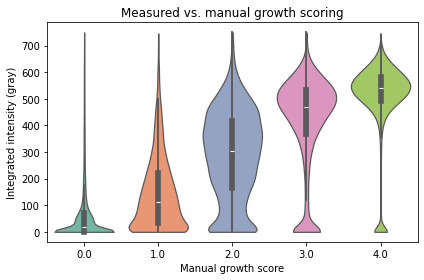

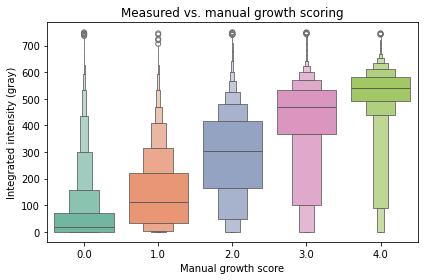

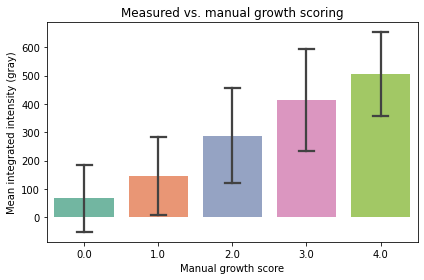

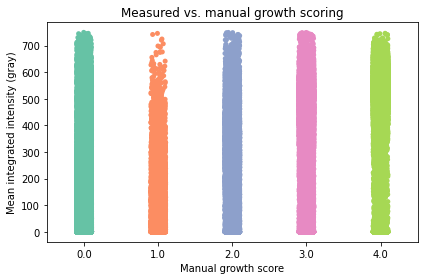

In [207]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()


# Plot
y      = scores_pd['manual_score_growth'].astype(int)

# Violin
plt.figure(figsize=(6, 4))
sns.violinplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    inner='box',         
    density_norm='width',
    cut=0,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# plt.ylim(0, 1800) # Trim outliers on plot
# Export plot
# violinValidationPlotPath = os.path.join(PATH, "violin_plot_validation_against_GT.png")
# plt.savefig(violinValidationPlotPath, dpi=300)
plt.show()

# Boxen
plt.figure(figsize=(6, 4))
sns.boxenplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
# plt.ylim(0, 1500) # Trim outliers on the plot
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# boxenValidationPlotPath = os.path.join(PATH, "boxen_plot_validation_against_GT.png")
# plt.savefig(boxenValidationPlotPath, dpi=300)
plt.show()

# Bar
plt.figure(figsize=(6, 4))
sns.barplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    errorbar='sd',   
    capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()


# swarmplot
plt.figure(figsize=(6, 4))
sns.stripplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    # errorbar='sd',   
    # capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()

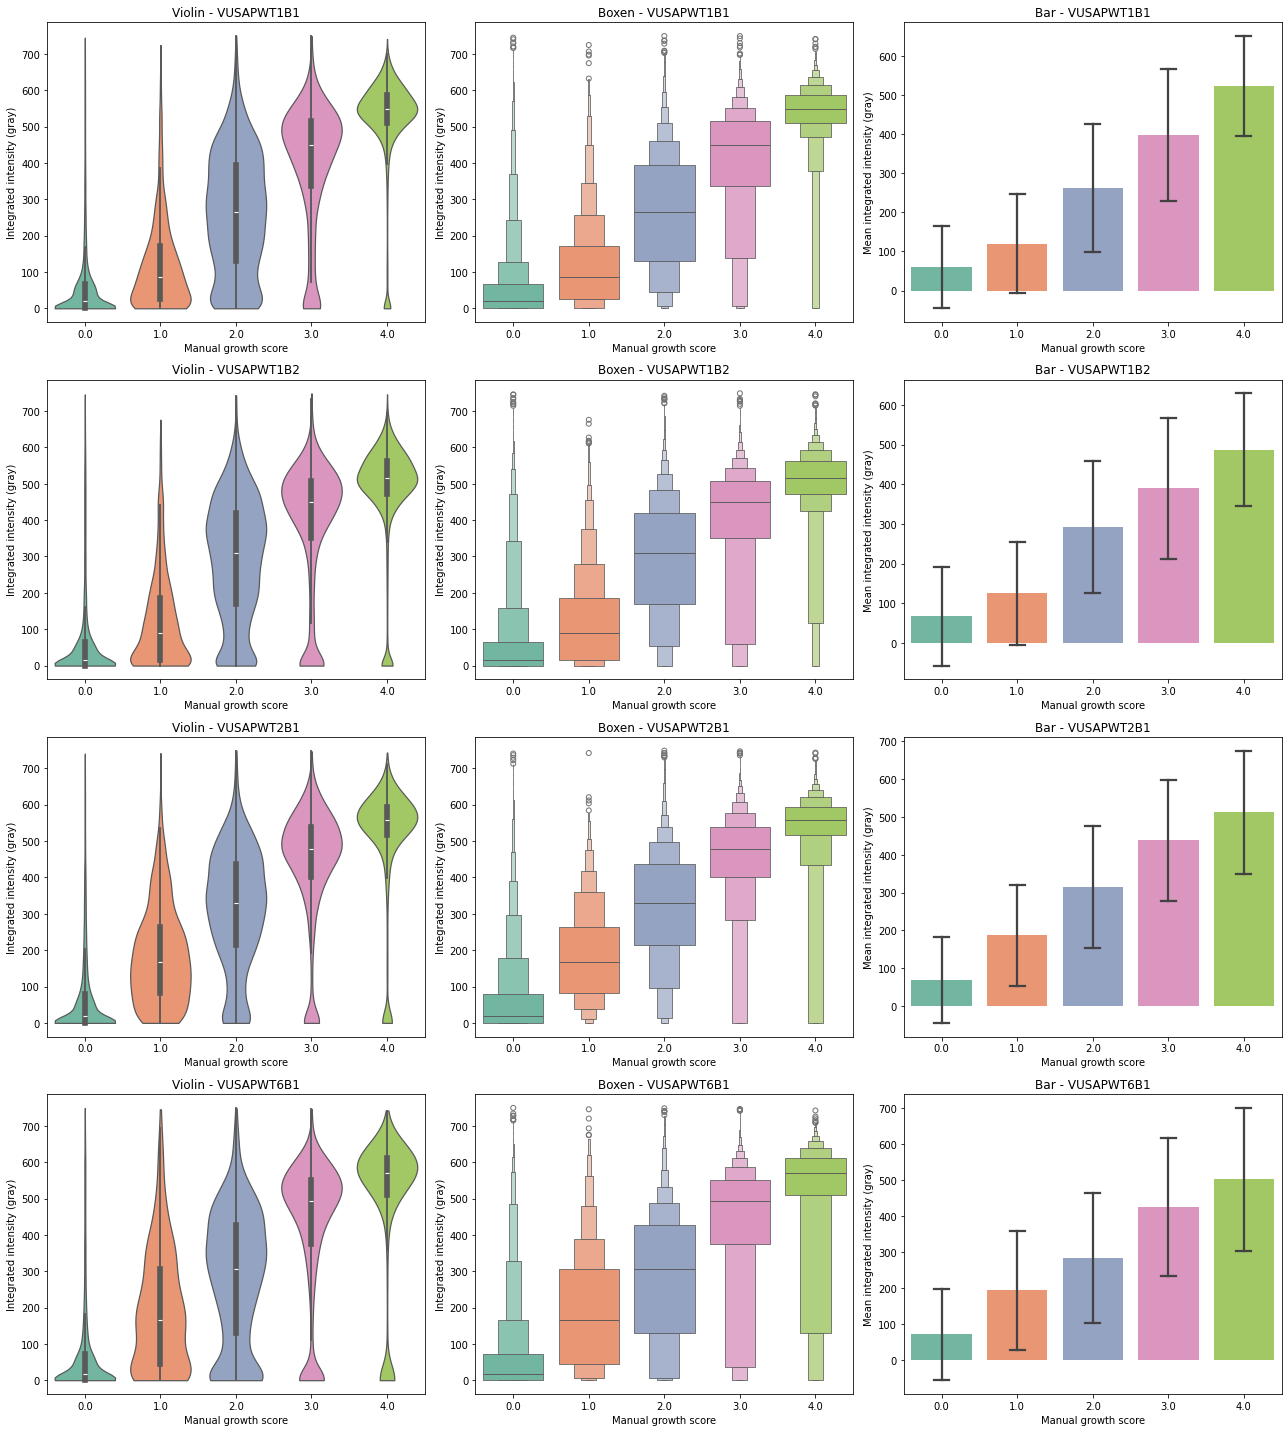

In [208]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()

# Get unique retest_batch values
unique_batches = scores_pd['retest_batch'].unique()
n_batches = len(unique_batches)

# Create figure with subplots: rows = batches, columns = 3 plot types
fig, axes = plt.subplots(n_batches, 3, figsize=(18, 5*n_batches))

# If only one batch, make sure axes is 2D
if n_batches == 1:
    axes = axes.reshape(1, -1)

plot_types = ['Violin', 'Boxen', 'Bar']

for i, batch in enumerate(unique_batches):
    batch_data = scores_pd[scores_pd['retest_batch'] == batch].copy()
    
    if len(batch_data) == 0:
        # Hide empty subplots
        for j in range(3):
            axes[i, j].set_visible(False)
        continue
    
    # Violin plot
    sns.violinplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        inner='box',         
        density_norm='width',
        cut=0,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 0]
    )
    axes[i, 0].set_xlabel('Manual growth score')
    axes[i, 0].set_ylabel('Integrated intensity (gray)')
    axes[i, 0].set_title(f'Violin - {batch}')

    # Boxen plot
    sns.boxenplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 1]
    )
    axes[i, 1].set_xlabel('Manual growth score')
    axes[i, 1].set_ylabel('Integrated intensity (gray)')
    axes[i, 1].set_title(f'Boxen - {batch}')

    # Bar plot
    sns.barplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        errorbar='sd',   
        capsize=0.2,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 2]
    )
    axes[i, 2].set_xlabel('Manual growth score')
    axes[i, 2].set_ylabel('Mean integrated intensity (gray)')
    axes[i, 2].set_title(f'Bar - {batch}')

plt.tight_layout()
plt.show()

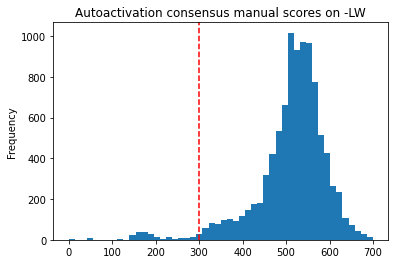

In [209]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LW')
].consensus_score.plot(kind='hist', bins=50, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

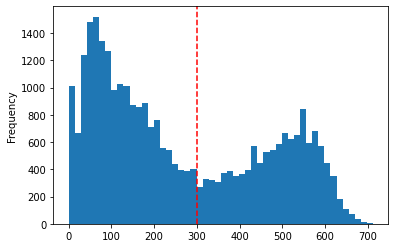

In [210]:

scores_pd[
    # (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LWH1')
].consensus_score.plot(kind='hist', bins=50)#, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

In [211]:
# print('Before filtering:')
# print(scores.shape)
# print('ppi_group', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ppi_group").n_unique()).item())
# print('db_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_orf_id").n_unique()).item())
# print('ad_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ad_orf_id").n_unique()).item())
# print('db_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_group").n_unique()).item())
# print('edge_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("edge_group").n_unique()).item())



# Usage example - replace your current print statements with:
# stats_before = get_filtering_stats(scores, aa_id, rrs_id, "Before filtering")
# print_filtering_stats(stats_before)

# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After aa mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After aa mating failure other media:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))


print('After mating failure LW step 1:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print('After mating failure LW step 2:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
)

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

print('remove aa rows:?')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# substract aa values or
# remove if aa value > x (300)?

scores_adjusted = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('after adjusted score:')
print(scores_adjusted.shape)
print('ppis', scores_adjusted.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

# alternative approach, remove rows where aa score is greater than 300
scores_300 = scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))

print('after aa > 300:')
print(scores_300.shape)
print('ppis', scores_300.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


scores = scores_300
scores

After aa mating failure LW:
(184043, 38)
ppis 4373
nodes 244
ads 777
48
After aa mating failure other media:
(184043, 38)
ppis 4373
nodes 244
ads 777
48
After mating failure LW step 1:
(177947, 38)
ppis 4151
nodes 244
ads 757
48
After mating failure LW step 2:
(156270, 38)
ppis 3648
nodes 232
ads 695
0
remove aa rows:?
(100989, 39)
ppis 3648
nodes 232
ads 695
0
after adjusted score:
(60689, 40)
ppis 3263
nodes 232
ads 695
after aa > 300:
(84017, 39)
ppis 3636
nodes 232
ads 695
0


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,9.41225,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,9.338735,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,9.25123,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,9.162974,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,9.42001,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_021""","""N16""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,100002000,null,2922,999999,"""RRS_VUS1_DB_2""","""B09""","""RRS_VUS1_AD_2""","""B09""",0.0,10.47451,false,5.918255,18.464379,"""TSPYL2""",null,null,null,null,null,null,null,null,null,"""2922.0_999999.0""","""2922.0_999999.0_LWAH1_VUSAPWT1…","""100002000.0_2922.0_999999.0_VU…","""100002000.0_2922.0_VUSAPWT1B1""","""NULL""",null,null,0.0
"""VUSAPWT1B1r06_021""","""O01""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,7880,null,3980,999999,

In [212]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,9.41225,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,9.338735,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,9.25123,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,9.162974,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,9.42001,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P16""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598,null,52920,218637,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",2.0,null,false,null,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VU

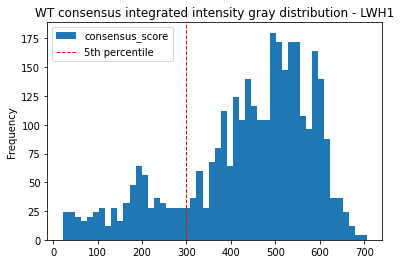

In [213]:
scores_pd = scores.to_pandas()
fig = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].consensus_score.plot(kind='hist', bins=50, title='WT consensus integrated intensity gray distribution - LWH1')

plt.axvline(300, color='red', linestyle='dashed', linewidth=1, label='5th percentile')
plt.legend()

In [214]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(pl.col("consensus_score") < 300)
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


wt_failures

removing WT failures:
(59538, 39)
ppis 2965
nodes 204
ads 633


['56717.0_53065.0_VUSAPWT1B2',
 '100064146.0_7465.0_VUSAPWT1B2',
 '4576.0_4062.0_VUSAPWT2B1',
 '13662.0_11895.0_VUSAPWT1B2',
 '6859.0_3643.0_VUSAPWT1B2',
 '100015297.0_13554.0_VUSAPWT6B1',
 '13791.0_53030.0_VUSAPWT1B2',
 '100080275.0_53737.0_VUSAPWT1B2',
 '100070143.0_13943.0_VUSAPWT1B2',
 '81261.0_7147.0_VUSAPWT6B1',
 '100070143.0_53965.0_VUSAPWT1B2',
 '100015584.0_5066.0_VUSAPWT2B1',
 '4569.0_3192.0_VUSAPWT1B2',
 '7912.0_4062.0_VUSAPWT2B1',
 '10844.0_7198.0_VUSAPWT6B1',
 '2658.0_2713.0_VUSAPWT6B1',
 '13667.0_55864.0_VUSAPWT1B2',
 '2304.0_7634.0_VUSAPWT1B2',
 '13795.0_8416.0_VUSAPWT1B2',
 '3931.0_71286.0_VUSAPWT1B2',
 '70835.0_3689.0_VUSAPWT1B2',
 '11539.0_2713.0_VUSAPWT6B1',
 '53886.0_6137.0_VUSAPWT1B2',
 '53212.0_54308.0_VUSAPWT1B1',
 '2261.0_6408.0_VUSAPWT1B2',
 '54957.0_53737.0_VUSAPWT1B2',
 '11423.0_53030.0_VUSAPWT6B1',
 '3148.0_71191.0_VUSAPWT6B1',
 '71152.0_10122.0_VUSAPWT2B1',
 '2099.0_70497.0_VUSAPWT1B1',
 '820.0_3581.0_VUSAPWT1B2',
 '2347.0_10950.0_VUSAPWT1B2',
 '55532.0_139

In [215]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score


In [216]:
# write out results
scores.write_csv(f"{outputs_dir}/3_automated_qaqc_consensus_scores.csv")

In [217]:
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
0,VUSAPWT1B1r01_016,A01,VUSAPWT1B1r01_013_014_015_016_017_018,VUSAPWT1B1,r07,LW,1,False,56215,NaN,52920,2678,VUSMutY8Dh007,A01,CEGSint_Y8A_4,F03,4.0,631.349047,False,9.412250,577.868327,HIP1,LITAF,Ala111Gly,332C>G,ENSG00000189067,RC4,1_Pathogenic,NaN,2.0,LITAF_Ala111Gly,52920.0_2678.0,52920.0_2678.0_LW_VUSAPWT1B1,56215.0_52920.0_2678.0_VUSAPWT1B1,56215.0_52920.0_VUSAPWT1B1,1,1,Y,NaN
1,VUSAPWT1B1r01_016,A02,VUSAPWT1B1r01_013_014_015_016_017_018,VUSAPWT1B1,r07,LW,1,False,56215,NaN,52920,2678,VUSMutY8Dh007,A01,CEGSint_Y8A_4,F03,4.0,597.499373,False,9.338735,577.868327,HIP1,LITAF,Ala111Gly,332C>G,ENSG00000189067,RC4,1_Pathogenic,NaN,2.0,LITAF_Ala111Gly,52920.0_2678.0,52920.0_2678.0_LW_VUSAPWT1B1,56215.0_52920.0_2678.0_VUSAPWT1B1,56215.0_52920.0_VUSAPWT1B1,1,1,Y,NaN
2,VUSAPWT1B1r01_016,B01,VUSAPWT1B1r01_013_014_015_016_017_018,VUSAPWT1B1,r07,LW,1,False,56215,NaN,52920,2678,VUSMutY8Dh007,A01,CEGSint_Y8A_4,F03,4.0,559.393490,False,9.251230,577.868327,HIP1,LITAF,Ala111Gly,332C>G,ENSG00000189067,RC4,1_Pathogenic,NaN,2.0,LITAF_Ala111Gly,52920.0_2678.0,52920.0_2678.0_LW_VUSAPWT1B1,56215.0_52920.0_2678.0_VUSAPWT1B1,56215.0_52920.0_VUSAPWT1B1,1,1,Y,NaN
3,VUSAPWT1B1r01_016,B02,VUSAPWT1B1r01_013_014_015_016_017_018,VUSAPWT1B1,r07,LW,1,False,56215,NaN,52920,2678,VUSMutY8Dh007,A01,CEGSint_Y8A_4,F03,4.0,523.231397,False,9.162974,577.868327,HIP1,LITAF,Ala111Gly,332C>G,ENSG00000189067,RC4,1_Pathogenic,NaN,2.0,LITAF_Ala111Gly,52920.0_2678.0,52920.0_2678.0_LW_VUSAPWT1B1,56215.0_52920.0_2678.0_VUSAPWT1B1,56215.0_52920.0_VUSAPWT1B1,1,1,Y,NaN
4,VUSAPWT1B1r01_016,E01,VUSAPWT1B1r01_013_014_015_016_017_018,VUSAPWT1B1,r07,LW,1,False,11567,NaN,52920,2678,VUSMutY8Dh007,A01,CEGSint_Y8A_5,A06,4.0,635.023557,False,9.420010,584.419307,TAX1BP1,LITAF,Ala111Gly,332C>G,ENSG00000189067,RC4,1_Pathogenic,NaN,2.0,LITAF_Ala111Gly,52920.0_2678.0,52920.0_2678.0_LW_VUSAPWT1B1,11567.0_52920.0_2678.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,Y,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59533,VUSAPWT1B1r06_033,P18,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,1769,NaN,3535,201190,VUSMutY8Dh018,D11,CEGSint_Y8A_6,D08,3.0,45.951635,False,6.584235,174.742486,CATSPER1,EMD,Met1Val,1A>G,ENSG00000102119,CEGS2,1_Pathogenic,9.500010e-07,2.0,EMD_Met1Val,3535.0_201190.0,3535.0_201190.0_LWAH1_VUSAPWT1B1,1769.0_3535.0_201190.0_VUSAPWT1B1,1769.0_3535.0_VUSAPWT1B1,1,1,Y,0.0
59534,VUSAPWT1B1r06_033,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,6811,NaN,4723,201739,VUSMutY8Dh019,H05,CEGSint_Y8A_3,A05,3.0,NaN,False,NaN,NaN,MAD1L1,TPM1,Leu185Arg,554T>G,ENSG00000140416,CEGS2,5_Others,NaN,NaN,TPM1_Leu185Arg,4723.0_201739.0,4723.0_201739.0_LWAH1_VUSAPWT1B1,6811.0_4723.0_201739.0_VUSAPWT1B1,6811.0_4723.0_VUSAPWT1B1,1,1,Y,0.0
59535,VUSAPWT1B1r06_033,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,6811,NaN,4723,201739,VUSMutY8Dh019,H05,CEGSint_Y8A_3,A05,3.0,NaN,False,NaN,NaN,MAD1L1,TPM1,Leu185Arg,554T>G,ENSG00000140416,CEGS2,5_Others,NaN,NaN,TPM1_Leu185Arg,4723.0_201739.0,4723.0_201739.0_LWAH1_VUSAPWT1B1,6811.0_4723.0_201739.0_VUSAPWT1B1,6811.0_4723.0_VUSAPWT1B1,1,1,Y,0.0
59536,VUSAPWT1B1r06_036,P15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,3598,NaN,52920,218637,VUSMutY8Dh022,F07,CEGSint_Y8A_6,B02,2.0,NaN,False,NaN,NaN,DAZAP2,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,Na

In [218]:
scoring_conditions

['LWH1', 'LWH10', 'LWH25', 'LWA']

In [219]:
scores_pd_nodup = scores_pd.drop_duplicates(subset=['db_condition_group'])
scores_pd_nodup = scores_pd_nodup[scores_pd_nodup.condition_name.isin(scoring_conditions)]
scores_pd_nodup

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
364,VUSAPWT1B1r02_001,A15,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,3.0,215.619611,False,8.053218,142.148042,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LWA_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None,0.000000
366,VUSAPWT1B1r02_001,A17,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,2.0,194.831376,False,7.935645,95.421243,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LWA_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None,0.000000
368,VUSAPWT1B1r02_001,A23,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,11567,NaN,52920,0,DisWTGDEh03,A05,CEGSint_Y8A_5,A06,4.0,513.037922,False,9.137088,468.773538,TAX1BP1,LITAF,None,None,ENSG00000189067,None,None,NaN,NaN,LITAF,52920.0_0.0,52920.0_0.0_LWA_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None,0.000000
376,VUSAPWT1B1r02_001,C03,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,12260,NaN,2651,0,DisWTGDEh02,G09,CEGSint_Y8A_7,B05,0.0,0.000000,False,5.643856,5.598366,STX1A,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6,2651.0_0.0,2651.0_0.0_LWA_VUSAPWT1B1,12260.0_2651.0_0.0_VUSAPWT1B1,12260.0_2651.0_VUSAPWT1B1,1,1,None,3.002941
378,VUSAPWT1B1r02_001,C07,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,5441,NaN,71892,0,DisWTGDEh03,B03,CEGSint_Y8A_5,B07,1.0,0.000000,False,5.643856,0.000000,PUF60,TH,None,None,ENSG00000180176,None,None,NaN,NaN,TH,71892.0_0.0,71892.0_0.0_LWA_VUSAPWT1B1,5441.0_71892.0_0.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,None,1.627778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58152,VUSAPWT1B1r05_033,C23,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,NaN,4723,201733,VUSMutY8Dh019,A06,CEGSint_Y8A_2,G09,4.0,569.171260,False,9.274195,508.678117,KXD1,TPM1,Ala63Val,188C>T,ENSG00000140416,CEGS2,1_Pathogenic,NaN,2.0,TPM1_Ala63Val,4723.0_201733.0,4723.0_201733.0_LWH25_VUSAPWT1B1,4621.0_4723.0_201733.0_VUSAPWT1B1,4621.0_4723.0_VUSAPWT1B1,1,1,Y,NaN
58210,VUSAPWT1B1r05_033,G11,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,6552,NaN,2713,200832,VUSMutY8Dh018,B04,CEGSint_Y8A_2,C06,0.0,89.342485,False,7.122491,76.993138,MAGEA8,MLH1,Gly147Arg,439G>C,ENSG00000076242,CEGS2,3_Conflicting,NaN,1.0,MLH1_Gly147Arg,2713.0_200832.0,2713.0_200832.0_LWH25_VUSAPWT1B1,6552.0_2713.0_200832.0_VUSAPWT1B1,6552.0_2713.0_VUSAPWT1B1,1,1,Y,171.551964
58254,VUSAPWT1B1r05_036,K19,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,9746,NaN,54308,218854,VUSMutY8Dh022,H09,CEGSint_Y8A_6,C02,3.0,567.921591,False,9.271280,545.528125,MTUS2,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser,54308.0_218854.0,54308.0_218854.0_LWH25_VUSAPWT1B1,9746.0_54308.0_218854.0_VUSAPWT1B1,9746.0_54308.0_VUSAPWT1B1,1,1,Y,NaN
58284,VUSAPWT1B1r05_033,M21,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,NaN,4723,201739,VUSMutY8Dh019,H05,CEGSint_Y8A_2,G09,4.0,516.050986,False,9.144788,526.463735,KXD1,TPM1,Leu185Arg,554T>G,ENSG00000140416,CEGS2,5_Others,NaN,NaN,TPM1_Leu185Arg,4723.0_201739.0,4723.0_201739.0_LWH25_VUSAPWT1B1,4621.0_4723.0_201739.0_VUSAPWT

In [220]:
for group, df in scores_pd_nodup.groupby('ppi_group'):
    print(f"Edge group: {group}")
    print("\n")
    
df

Edge group: 100000046.0_7323.0_0.0_VUSAPWT6B1


Edge group: 100000046.0_7323.0_216370.0_VUSAPWT6B1


Edge group: 100000046.0_7323.0_216371.0_VUSAPWT6B1


Edge group: 100000400.0_100000400.0_221528.0_VUSAPWT1B2


Edge group: 100000407.0_10177.0_0.0_VUSAPWT1B2


Edge group: 100000407.0_13597.0_0.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200922.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200923.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200926.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200927.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200930.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200931.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200932.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200933.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200934.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200935.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200938.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200940.0_VUSAPWT1B2


Edge group: 100000407.0_2803.0_200941.0_VUSAPWT1B2


E

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
33604,VUSAPWT2B1r02_007,C21,VUSAPWT2B1r02_007_008_009_010_011_012,VUSAPWT2B1,r14,LWA,2,False,9980,NaN,5933,0,DisWTY8Dh02,A08,CEGSint_Y8A2_1,B12,2.0,536.615703,False,9.196272,454.779426,POU2AF1,TFG,None,None,ENSG00000114354,None,None,NaN,NaN,TFG,5933.0_0.0,5933.0_0.0_LWA_VUSAPWT2B1,9980.0_5933.0_0.0_VUSAPWT2B1,9980.0_5933.0_VUSAPWT2B1,1,1,None,13.311438
35324,VUSAPWT2B1r03_007,C21,VUSAPWT2B1r03_007_008_009_010_011_012,VUSAPWT2B1,r15,LWH1,2,False,9980,NaN,5933,0,DisWTY8Dh02,A08,CEGSint_Y8A2_1,B12,2.0,440.360798,False,8.937700,368.174195,POU2AF1,TFG,None,None,ENSG00000114354,None,None,NaN,NaN,TFG,5933.0_0.0,5933.0_0.0_LWH1_VUSAPWT2B1,9980.0_5933.0_0.0_VUSAPWT2B1,9980.0_5933.0_VUSAPWT2B1,1,1,None,79.704903
36968,VUSAPWT2B1r04_007,C21,VUSAPWT2B1r04_007_008_009_010_011_012,VUSAPWT2B1,r16,LWH10,2,False,9980,NaN,5933,0,DisWTY8Dh02,A08,CEGSint_Y8A2_1,B12,2.0,391.379098,False,8.785874,451.967008,POU2AF1,TFG,None,None,ENSG00000114354,None,None,NaN,NaN,TFG,5933.0_0.0,5933.0_0.0_LWH10_VUSAPWT2B1,9980.0_5933.0_0.0_VUSAPWT2B1,9980.0_5933.0_VUSAPWT2B1,1,1,None,26.090523
38712,VUSAPWT2B1r05_007,C21,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,9980,NaN,5933,0,DisWTY8Dh02,A08,CEGSint_Y8A2_1,B12,2.0,474.138577,False,9.033804,439.543151,POU2AF1,TFG,None,None,ENSG00000114354,None,None,NaN,NaN,TFG,5933.0_0.0,5933.0_0.0_LWH25_VUSAPWT2B1,9980.0_5933.0_0.0_VUSAPWT2B1,9980.0_5933.0_VUSAPWT2B1,1,1,None,96.062093


Too many PPI groups (200) for legend - skipping legend


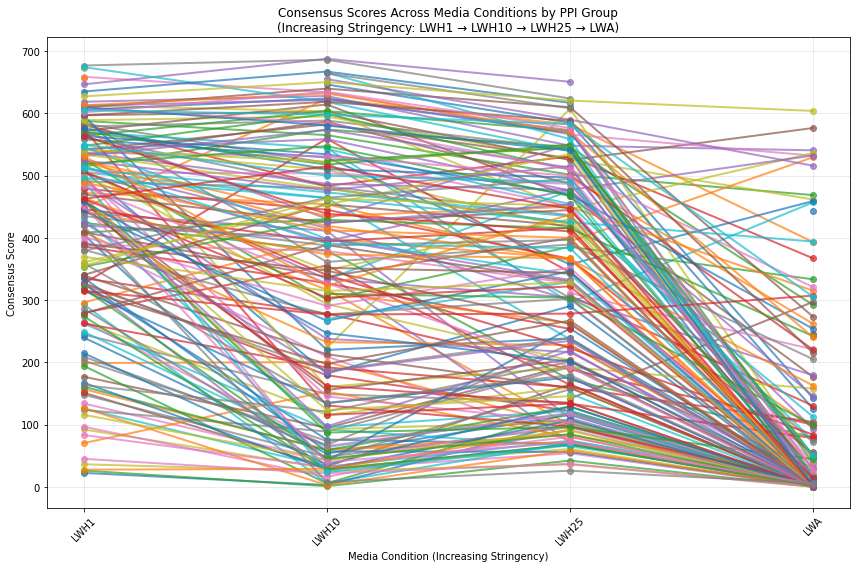

Plot created with 200 PPI groups as curves
X-axis order should be: ['LWH1', 'LWH10', 'LWH25', 'LWA']


In [221]:

import matplotlib.pyplot as plt
import seaborn as sns

subset = scores_pd_nodup

# Get unique PPI groups and limit to first 20
unique_ppi_groups = scores_pd_nodup['ppi_group'].unique()[:200]

# Create a single figure
plt.figure(figsize=(12, 8))

# Plot each PPI group as a separate curve
for ppi_group in unique_ppi_groups:
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    # Ensure we have all scoring conditions and order them correctly
    group_data = group_data[group_data['condition_name'].isin(scoring_conditions)]
    
    # Create ordered categorical for proper x-axis ordering
    group_data['condition_name'] = pd.Categorical(
        group_data['condition_name'], 
        categories=scoring_conditions,  # This should be ['LWH1', 'LWH10', 'LWH25', 'LWA']
        ordered=True
    )
    
    # Sort by condition for proper line plot
    group_data = group_data.sort_values('condition_name')
    
    # Convert categorical to numeric positions for plotting
    group_data['condition_position'] = group_data['condition_name'].cat.codes
    
    # Plot consensus scores across conditions as a curve
    if len(group_data) > 0:
        plt.plot(group_data['condition_position'], group_data['consensus_score'], 
                marker='o', linewidth=2, markersize=6, alpha=0.7, label=ppi_group)

plt.xlabel('Media Condition (Increasing Stringency)')
plt.ylabel('Consensus Score')
plt.title('Consensus Scores Across Media Conditions by PPI Group\n(Increasing Stringency: LWH1 → LWH10 → LWH25 → LWA)')
plt.grid(True, alpha=0.3)

# Set the x-axis ticks and labels to match the scoring conditions
plt.xticks(range(len(scoring_conditions)), scoring_conditions, rotation=45)

# Add legend (you might want to limit this if there are too many groups)
if len(unique_ppi_groups) <= 20:
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
else:
    print(f"Too many PPI groups ({len(unique_ppi_groups)}) for legend - skipping legend")


plt.tight_layout()
plt.show()

print(f"Plot created with {len(unique_ppi_groups)} PPI groups as curves")
print(f"X-axis order should be: {scoring_conditions}")

Too many PPI groups (1069) for legend - skipping legend


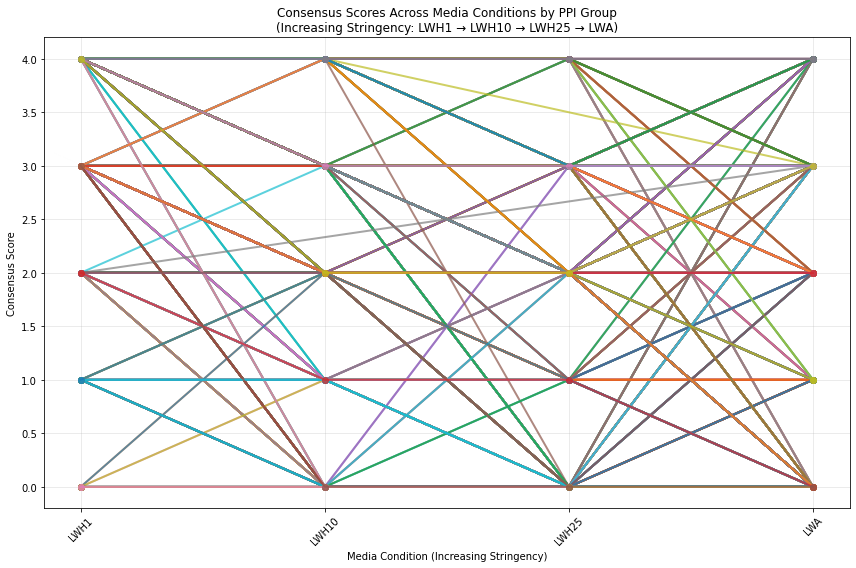

Plot created with 1069 PPI groups as curves
X-axis order should be: ['LWH1', 'LWH10', 'LWH25', 'LWA']


In [222]:

import matplotlib.pyplot as plt
import seaborn as sns

subset = scores_pd_nodup

# Get unique PPI groups and limit to first 20
unique_ppi_groups = scores_pd_nodup['ppi_group'].unique()#[:200]

# Create a single figure
plt.figure(figsize=(12, 8))

# Plot each PPI group as a separate curve
for ppi_group in unique_ppi_groups:
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    # Ensure we have all scoring conditions and order them correctly
    group_data = group_data[group_data['condition_name'].isin(scoring_conditions)]
    
    # Create ordered categorical for proper x-axis ordering
    group_data['condition_name'] = pd.Categorical(
        group_data['condition_name'], 
        categories=scoring_conditions,  # This should be ['LWH1', 'LWH10', 'LWH25', 'LWA']
        ordered=True
    )
    
    # Sort by condition for proper line plot
    group_data = group_data.sort_values('condition_name')
    
    # Convert categorical to numeric positions for plotting
    group_data['condition_position'] = group_data['condition_name'].cat.codes
    
    # Plot consensus scores across conditions as a curve
    if len(group_data) > 0:
        plt.plot(group_data['condition_position'], group_data['manual_score_growth'], 
                marker='o', linewidth=2, markersize=6, alpha=0.7, label=ppi_group)

plt.xlabel('Media Condition (Increasing Stringency)')
plt.ylabel('Consensus Score')
plt.title('Consensus Scores Across Media Conditions by PPI Group\n(Increasing Stringency: LWH1 → LWH10 → LWH25 → LWA)')
plt.grid(True, alpha=0.3)

# Set the x-axis ticks and labels to match the scoring conditions
plt.xticks(range(len(scoring_conditions)), scoring_conditions, rotation=45)

# Add legend (you might want to limit this if there are too many groups)
if len(unique_ppi_groups) <= 20:
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
else:
    print(f"Too many PPI groups ({len(unique_ppi_groups)}) for legend - skipping legend")


plt.tight_layout()
plt.show()

print(f"Plot created with {len(unique_ppi_groups)} PPI groups as curves")
print(f"X-axis order should be: {scoring_conditions}")

In [223]:
# ...existing code...

# Count PPI groups with monotonically decreasing scores across media stringency
def check_monotonic_decrease(group_data, score_column='consensus_score'):
    """
    Check if scores are monotonically decreasing across media conditions
    """
    # Ensure we have all scoring conditions and order them correctly
    group_data = group_data[group_data['condition_name'].isin(scoring_conditions)]
    
    if len(group_data) != len(scoring_conditions):
        return False, False, []  # Return tuple instead of just False
    
    # Create ordered categorical for proper ordering
    group_data['condition_name'] = pd.Categorical(
        group_data['condition_name'], 
        categories=scoring_conditions,
        ordered=True
    )
    
    # Sort by condition
    group_data = group_data.sort_values('condition_name')
    
    # Get scores in order
    scores = group_data[score_column].values
    
    # Check if any scores are NaN
    if pd.isna(scores).any():
        return False, False, scores
    
    # Check if strictly decreasing or non-increasing
    is_strictly_decreasing = all(scores[i] > scores[i+1] for i in range(len(scores)-1))
    is_non_increasing = all(scores[i] >= scores[i+1] for i in range(len(scores)-1))
    
    return is_strictly_decreasing, is_non_increasing, scores

# Apply to consensus scores
decreasing_counts = {'strictly_decreasing': 0, 'non_increasing': 0, 'total_groups': 0, 'groups_with_all_conditions': 0}

for ppi_group in scores_pd_nodup['ppi_group'].unique():
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    strictly_dec, non_inc, scores_array = check_monotonic_decrease(group_data, 'consensus_score')
    
    decreasing_counts['total_groups'] += 1
    
    # Only count groups that have all conditions
    if len(scores_array) == len(scoring_conditions):
        decreasing_counts['groups_with_all_conditions'] += 1
        if strictly_dec:
            decreasing_counts['strictly_decreasing'] += 1
        if non_inc:
            decreasing_counts['non_increasing'] += 1

print("Consensus Scores:")
print(f"Total PPI groups analyzed: {decreasing_counts['total_groups']}")
print(f"Groups with all conditions: {decreasing_counts['groups_with_all_conditions']}")
print(f"Groups with strictly decreasing scores: {decreasing_counts['strictly_decreasing']} ({decreasing_counts['strictly_decreasing']/decreasing_counts['groups_with_all_conditions']*100:.1f}% of complete groups)" if decreasing_counts['groups_with_all_conditions'] > 0 else "No complete groups found")
print(f"Groups with non-increasing scores: {decreasing_counts['non_increasing']} ({decreasing_counts['non_increasing']/decreasing_counts['groups_with_all_conditions']*100:.1f}% of complete groups)" if decreasing_counts['groups_with_all_conditions'] > 0 else "No complete groups found")

# Apply to manual scores
manual_decreasing_counts = {'strictly_decreasing': 0, 'non_increasing': 0, 'total_groups': 0, 'groups_with_all_conditions': 0}

for ppi_group in scores_pd_nodup['ppi_group'].unique():
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    # Skip if no manual scores
    if group_data['manual_score_growth'].isna().all():
        continue
        
    strictly_dec, non_inc, scores_array = check_monotonic_decrease(group_data, 'manual_score_growth')
    
    manual_decreasing_counts['total_groups'] += 1
    
    # Only count groups that have all conditions and valid scores
    if len(scores_array) == len(scoring_conditions) and not pd.isna(scores_array).any():
        manual_decreasing_counts['groups_with_all_conditions'] += 1
        if strictly_dec:
            manual_decreasing_counts['strictly_decreasing'] += 1
        if non_inc:
            manual_decreasing_counts['non_increasing'] += 1

print("\nManual Scores:")
print(f"Total PPI groups analyzed: {manual_decreasing_counts['total_groups']}")
print(f"Groups with all conditions: {manual_decreasing_counts['groups_with_all_conditions']}")
print(f"Groups with strictly decreasing scores: {manual_decreasing_counts['strictly_decreasing']} ({manual_decreasing_counts['strictly_decreasing']/manual_decreasing_counts['groups_with_all_conditions']*100:.1f}% of complete groups)" if manual_decreasing_counts['groups_with_all_conditions'] > 0 else "No complete groups found")
print(f"Groups with non-increasing scores: {manual_decreasing_counts['non_increasing']} ({manual_decreasing_counts['non_increasing']/manual_decreasing_counts['groups_with_all_conditions']*100:.1f}% of complete groups)" if manual_decreasing_counts['groups_with_all_conditions'] > 0 else "No complete groups found")

# Get examples of strictly decreasing groups
print("\nExamples of strictly decreasing consensus score groups:")
example_count = 0
for ppi_group in scores_pd_nodup['ppi_group'].unique():
    if example_count >= 5:  # Show first 5 examples
        break
        
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    strictly_dec, non_inc, scores_array = check_monotonic_decrease(group_data, 'consensus_score')
    
    if strictly_dec:
        print(f"{ppi_group}: {scores_array}")
        example_count += 1

Consensus Scores:
Total PPI groups analyzed: 1069
Groups with all conditions: 1002
Groups with strictly decreasing scores: 226 (22.6% of complete groups)
Groups with non-increasing scores: 226 (22.6% of complete groups)

Manual Scores:
Total PPI groups analyzed: 1069
Groups with all conditions: 980
Groups with strictly decreasing scores: 23 (2.3% of complete groups)
Groups with non-increasing scores: 708 (72.2% of complete groups)

Examples of strictly decreasing consensus score groups:
13662.0_70497.0_0.0_VUSAPWT1B1: [472.34740114 454.03106032 363.75621819  95.42124346]
11567.0_52920.0_0.0_VUSAPWT1B1: [588.05656258 565.11603453 501.58269145 468.77353831]
12260.0_2651.0_0.0_VUSAPWT1B1: [327.3980461  179.28627817 121.86634152   5.59836613]
6552.0_2713.0_0.0_VUSAPWT1B1: [583.74185827 520.55295596 303.58529773   0.        ]
9746.0_54308.0_0.0_VUSAPWT1B1: [505.39282274 464.25230154 237.0006573    0.        ]


## summing score

In [224]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# First, sum adjusted scores across conditions for each variant
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# Get WT scores (db_mut_id == 0) for normalization
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
)
# .select([
#     "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
#     "summed_consensus_score", "wt_summed_score", 'condition_name'
# ])

# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

204
204
195


ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group
i64,i64,i64,str,f64,f64,str,str,str
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH10""","""1""","""573_53030_0_VUSAPWT1B2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH25""","""1""","""573_53030_0_VUSAPWT1B2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH1""","""1""","""573_53030_0_VUSAPWT1B2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWA""","""1""","""573_53030_0_VUSAPWT1B2"""
13768,71191,205705,"""VUSAPWT6B1""",3196.832788,6586.915209,"""LWA""","""6""","""13768_71191_205705_VUSAPWT6B1"""
…,…,…,…,…,…,…,…,…
53964,2713,200856,"""VUSAPWT1B1""",3933.457651,5154.124323,"""LWH10""","""1""","""53964_2713_200856_VUSAPWT1B1"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWH25""","""6""","""56139_4062_201427_VUSAPWT6B1"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWA""","""6""","""56139_4062_201427_VUSAPWT6B1"""


In [225]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


(9259, 9)
ppis 2359
nodes 204
ads 633


In [226]:
# cast all to same format
summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

summed_scores = summed_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
summed_scores = summed_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
summed_scores = summed_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db
i64,i64,i64,str,f64,f64,str,str,str,str,str
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH10""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH25""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH1""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWA""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1"""
13768,71191,205705,"""VUSAPWT6B1""",3196.832788,6586.915209,"""LWA""","""6""","""13768_71191_205705_VUSAPWT6B1""","""1""","""1"""
…,…,…,…,…,…,…,…,…,…,…
53964,2713,200856,"""VUSAPWT1B1""",3933.457651,5154.124323,"""LWH10""","""1""","""53964_2713_200856_VUSAPWT1B1""","""1""","""1"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWH25""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWA""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1"""


In [227]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol
i64,i64,i64,str,f64,f64,str,str,str,str,str,str
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH10""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH25""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH1""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWA""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2"""
13768,71191,205705,"""VUSAPWT6B1""",3196.832788,6586.915209,"""LWA""","""6""","""13768_71191_205705_VUSAPWT6B1""","""1""","""1""","""UBR2"""
…,…,…,…,…,…,…,…,…,…,…,…
53964,2713,200856,"""VUSAPWT1B1""",3933.457651,5154.124323,"""LWH10""","""1""","""53964_2713_200856_VUSAPWT1B1""","""1""","""1""","""NFIX"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWH25""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1""","""TMEM52B"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWA""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1""","""TMEM52B"""


In [228]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH10""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2""","""FAM161A""",null,null,"""ENSG00000170264""",null,null,null,null,"""FAM161A"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH25""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2""","""FAM161A""",null,null,"""ENSG00000170264""",null,null,null,null,"""FAM161A"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWH1""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2""","""FAM161A""",null,null,"""ENSG00000170264""",null,null,null,null,"""FAM161A"""
573,53030,0,"""VUSAPWT1B2""",9250.880138,9250.880138,"""LWA""","""1""","""573_53030_0_VUSAPWT1B2""","""1""","""1""","""HOOK2""","""FAM161A""",null,null,"""ENSG00000170264""",null,null,null,null,"""FAM161A"""
13768,71191,205705,"""VUSAPWT6B1""",3196.832788,6586.915209,"""LWA""","""6""","""13768_71191_205705_VUSAPWT6B1""","""1""","""1""","""UBR2""","""SUOX""","""Gly530Asp""","""1589G>A""","""ENSG00000139531""","""CEGS2""","""1_Pathogenic""",6.8412e-7,null,"""SUOX_Gly530Asp"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
53964,2713,200856,"""VUSAPWT1B1""",3933.457651,5154.124323,"""LWH10""","""1""","""53964_2713_200856_VUSAPWT1B1""","""1""","""1""","""NFIX""","""MLH1""","""Asp304Gly""","""911A>G""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",6.8405e-7,1.0,"""MLH1_Asp304Gly"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWH25""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1""","""TMEM52B""","""PLP1""","""Asp168His""","""502G>C""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,null,"""PLP1_Asp168His"""
56139,4062,201427,"""VUSAPWT6B1""",3107.496819,8919.040882,"""LWA""","""6""","""56139_4062_201427_VUSAPWT6B1""","""1""","""1""","""TMEM52B""","""PLP1""","""Asp168His""","""502G>C""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,null,"""PLP1_Asp168His"""


In [229]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())

(9259, 21)
ppis 2359


In [230]:
# Create a filtered version for saving - keep only one row per unique combination
summed_scores_for_export = summed_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
summed_scores_for_export
# Write the filtered version (with only 1 row per combination)
summed_scores_for_export.write_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")

In [231]:
summed_scores_for_export_pd = summed_scores_for_export.to_pandas()

In [232]:
summed_scores_for_export_pd['log2fc'] = np.log2((summed_scores_for_export_pd['summed_consensus_score'] + 1) / (summed_scores_for_export_pd['wt_summed_score'] + 1))
summed_scores_for_export_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
0,54647,3535,0,VUSAPWT1B1,1594.760803,1594.760803,LWH10,1,54647_3535_0_VUSAPWT1B1,1,1,TRAF3IP3,EMD,None,None,ENSG00000102119,None,None,NaN,NaN,EMD,0.000000
1,199,7652,1834,VUSAPWT6B1,718.771250,2813.825792,LWH25,6,199_7652_1834_VUSAPWT6B1,1,1,SYTL4,STXBP1,Met443Arg,1328T>G,ENSG00000136854,RC4,1_Pathogenic,NaN,NaN,STXBP1_Met443Arg,-1.967435
2,4836,7038,0,VUSAPWT6B1,5083.265988,5083.265988,LWH10,6,4836_7038_0_VUSAPWT6B1,1,1,RHBDD2,DIABLO,None,None,ENSG00000184047,None,None,NaN,NaN,DIABLO,0.000000
3,100064148,56278,0,VUSAPWT1B2,2382.098071,2382.098071,LWH1,1,100064148_56278_0_VUSAPWT1B2,1,1,KRTAP12-3,CHRNG,None,None,ENSG00000196811,None,None,NaN,NaN,CHRNG,0.000000
4,71001,52920,2685,VUSAPWT1B1,8622.616048,8344.078741,LWA,1,71001_52920_2685_VUSAPWT1B1,1,1,UBQLN2,LITAF,Thr49Met,146C>T,ENSG00000189067,RC4,3_Conflicting,NaN,1.0,LITAF_Thr49Met,0.047367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2354,4616,4004,0,VUSAPWT6B1,5111.098217,5111.098217,LWH1,6,4616_4004_0_VUSAPWT6B1,1,1,UBE2I,FADD,None,None,ENSG00000168040,None,None,NaN,NaN,FADD,0.000000
2355,13628,7323,216371,VUSAPWT2B1,8072.787210,7015.946630,LWH10,2,13628_7323_216371_VUSAPWT2B1,1,1,KLRC1,PMP22,Arg157Trp,469C>T,ENSG00000109099,CEGS2,1_Pathogenic,NaN,2.0,PMP22_Arg157Trp,0.202402
2356,138,6395,0,VUSAPWT1B2,5107.908590,5107.908590,LWH10,1,138_6395_0_VUSAPWT1B2,1,1,MYD88,IRAK4,None,None,ENSG00000198001,None,None,NaN,NaN,IRAK4,0.000000
2357,1227,12343,0,VUSAPWT1B2,3003.796135,3003.796135,LWA,1,1227_12343_0_VUSAPWT1B2,1,1,TRIM23,CDC73,None,None,ENSG00000134371,None,None,NaN,NaN,CDC73,0.000000


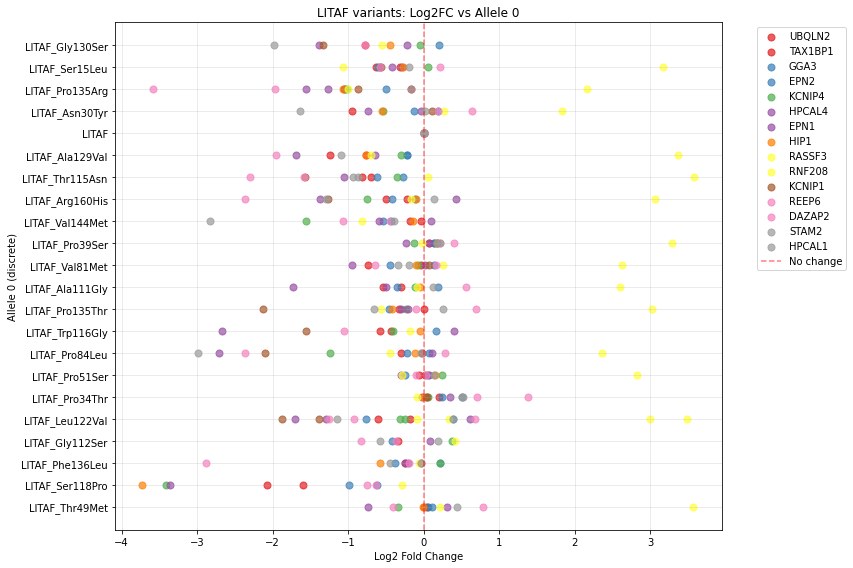

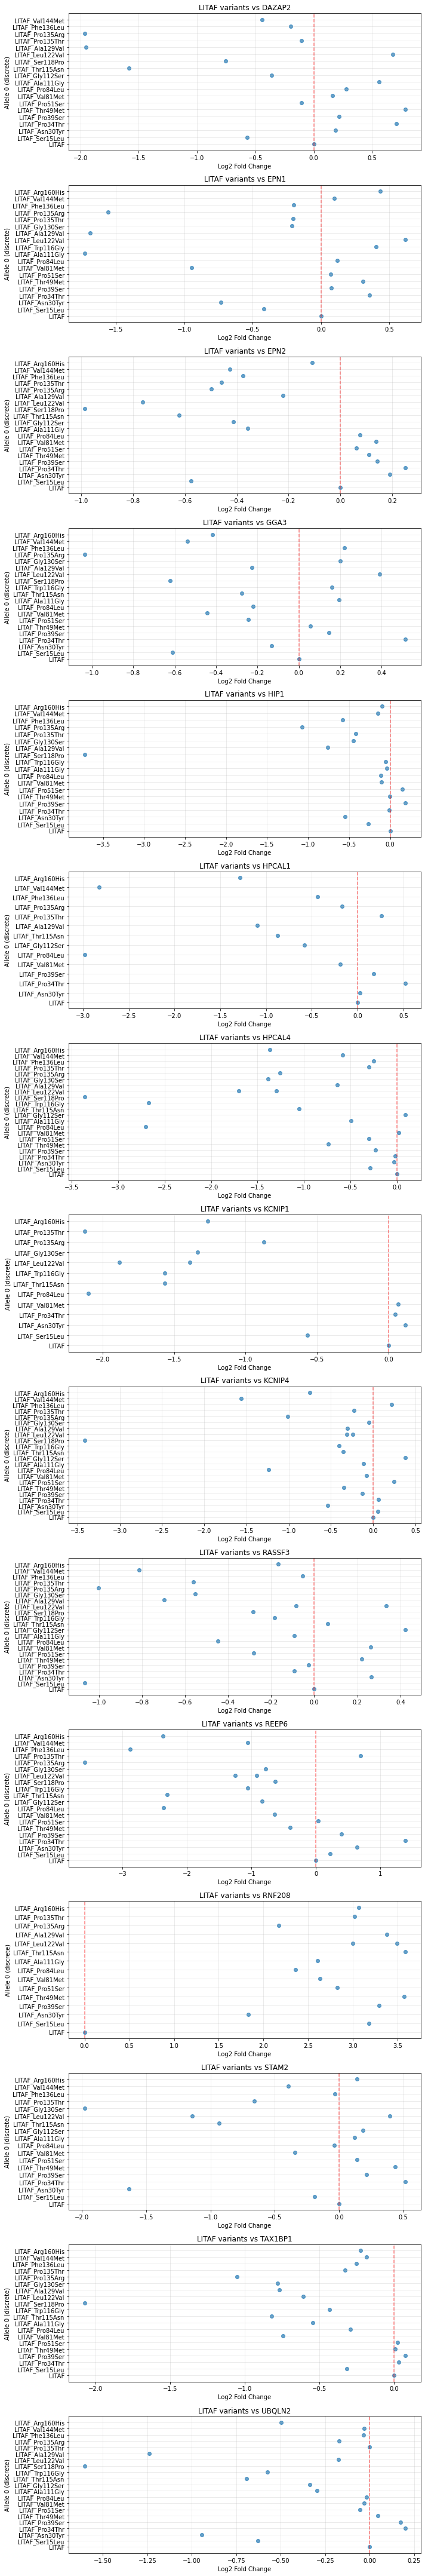

Figure saved to: ../3_outputs/sqY2H/LITAF_variants_log2fc_vs_allele0_subplots.png


In [233]:
# Filter for LITAF data
litaf = summed_scores_for_export_pd[summed_scores_for_export_pd.symbol == 'LITAF']

# Create scatter plot with log2fc on x-axis and allele_0 on y-axis
plt.figure(figsize=(12, 8))

# Get unique interactors for color coding
unique_interactors = litaf['ad_symbol'].unique()
colors = plt.cm.Set1(np.linspace(0, 1, len(unique_interactors)))

for i, interactor in enumerate(unique_interactors):
    interactor_data = litaf[litaf['ad_symbol'] == interactor]
    plt.scatter(interactor_data['log2fc'], interactor_data['allele_0'], 
               alpha=0.7, label=interactor, color=colors[i], s=50)

# Add vertical line at x=0 for reference
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='No change')

plt.xlabel('Log2 Fold Change')
plt.ylabel('Allele 0 (discrete)')
plt.title('LITAF variants: Log2FC vs Allele 0')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# ...existing code...

# Alternative: Create separate plots for each interactor with sorted alleles
unique_interactors = sorted(litaf['ad_symbol'].unique())
n_interactors = len(unique_interactors)

# Sort allele_0 values by position number (extract number from strings like "LITAF_Arg12Pro")
import re

def extract_position(allele_name):
    """Extract position number from allele name like 'LITAF_Arg12Pro'"""
    match = re.search(r'(\d+)', allele_name)
    return int(match.group(1)) if match else 0

unique_allele_0 = sorted(litaf['allele_0'].unique(), key=extract_position)

# Create a mapping from allele name to sorted position
allele_to_position = {allele: i for i, allele in enumerate(unique_allele_0)}

fig, axes = plt.subplots(n_interactors, 1, figsize=(10, 4*n_interactors))

# If only one interactor, make sure axes is iterable
if n_interactors == 1:
    axes = [axes]

for i, interactor in enumerate(unique_interactors):
    interactor_data = litaf[litaf['ad_symbol'] == interactor].copy()
    
    # Only include alleles that have data for this specific interactor
    available_alleles = interactor_data['allele_0'].unique()
    
    # Filter and sort only the alleles that have data for this interactor
    available_alleles_sorted = sorted(available_alleles, key=extract_position)
    
    # Create a mapping from available allele names to their sorted positions
    allele_to_position = {allele: j for j, allele in enumerate(available_alleles_sorted)}
    
    # Map allele names to their sorted positions
    interactor_data['allele_position'] = interactor_data['allele_0'].map(allele_to_position)
    
    # Create scatter plot using the mapped positions
    axes[i].scatter(interactor_data['log2fc'], interactor_data['allele_position'], alpha=0.7)
    
    # Add vertical line at x=0 for reference
    axes[i].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    
    # Customize plot
    axes[i].set_xlabel('Log2 Fold Change')
    axes[i].set_ylabel('Allele 0 (discrete)')
    axes[i].set_title(f'LITAF variants vs {interactor}')
    axes[i].grid(True, alpha=0.3)
    
    # Set y-tick labels to show only the alleles available for this interactor
    axes[i].set_yticks(range(len(available_alleles_sorted)))
    axes[i].set_yticklabels(available_alleles_sorted, ha='right')

plt.tight_layout()

# Save the figure
plt.savefig(f"{outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.png", 
            dpi=300, bbox_inches='tight')
plt.savefig(f"{outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.pdf", 
            bbox_inches='tight')
plt.show()

print(f"Figure saved to: {outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.png")

In [234]:
summed_scores_for_export_pd_pl = pl.DataFrame(summed_scores_for_export_pd)
summed_scores_for_export_pd_pl

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
i64,i64,i64,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64
54647,3535,0,"""VUSAPWT1B1""",1594.760803,1594.760803,"""LWH10""","""1""","""54647_3535_0_VUSAPWT1B1""","""1""","""1""","""TRAF3IP3""","""EMD""",null,null,"""ENSG00000102119""",null,null,null,null,"""EMD""",0.0
199,7652,1834,"""VUSAPWT6B1""",718.77125,2813.825792,"""LWH25""","""6""","""199_7652_1834_VUSAPWT6B1""","""1""","""1""","""SYTL4""","""STXBP1""","""Met443Arg""","""1328T>G""","""ENSG00000136854""","""RC4""","""1_Pathogenic""",null,null,"""STXBP1_Met443Arg""",-1.967435
4836,7038,0,"""VUSAPWT6B1""",5083.265988,5083.265988,"""LWH10""","""6""","""4836_7038_0_VUSAPWT6B1""","""1""","""1""","""RHBDD2""","""DIABLO""",null,null,"""ENSG00000184047""",null,null,null,null,"""DIABLO""",0.0
100064148,56278,0,"""VUSAPWT1B2""",2382.098071,2382.098071,"""LWH1""","""1""","""100064148_56278_0_VUSAPWT1B2""","""1""","""1""","""KRTAP12-3""","""CHRNG""",null,null,"""ENSG00000196811""",null,null,null,null,"""CHRNG""",0.0
71001,52920,2685,"""VUSAPWT1B1""",8622.616048,8344.078741,"""LWA""","""1""","""71001_52920_2685_VUSAPWT1B1""","""1""","""1""","""UBQLN2""","""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",0.047367
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
4616,4004,0,"""VUSAPWT6B1""",5111.098217,5111.098217,"""LWH1""","""6""","""4616_4004_0_VUSAPWT6B1""","""1""","""1""","""UBE2I""","""FADD""",null,null,"""ENSG00000168040""",null,null,null,null,"""FADD""",0.0
13628,7323,216371,"""VUSAPWT2B1""",8072.78721,7015.94663,"""LWH10""","""2""","""13628_7323_216371_VUSAPWT2B1""","""1""","""1""","""KLRC1""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""",0.202402
138,6395,0,"""VUSAPWT1B2""",5107.90859,5107.90859,"""LWH10""","""1""","""138_6395_0_VUSAPWT1B2""","""1""","""1""","""MYD88""","""IRAK4""",null,null,"""ENSG00000198001""",null,null,null,null,"""IRAK4""",0.0


In [235]:
# Find edges (ad_orf_id, db_orf_id, retest_batch) with WT data
edges_with_wt = summed_scores_for_export_pd_pl.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Find edges with variant data  
edges_with_variants = summed_scores_for_export_pd_pl.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Get intersection - edges that have both WT and variants
edges_with_both = edges_with_wt.join(
    edges_with_variants, 
    on=["db_orf_id"],#, "ad_orf_id", "retest_batch"], 
    how="inner"
)

# Filter summed_scores_for_export_pd_pl to only include these edges
summed_scores_for_export_pd_pl_filtered = summed_scores_for_export_pd_pl.join(
    edges_with_both,
    on=["db_orf_id"],# "ad_orf_id", "retest_batch"],
    how="inner"
)

In [236]:
ummed_scores_for_export_pd_pl_filtered = summed_scores_for_export_pd_pl_filtered.filter(pl.col("db_mut_id") != 0)
ummed_scores_for_export_pd_pl_filtered

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
i64,i64,i64,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64
199,7652,1834,"""VUSAPWT6B1""",718.77125,2813.825792,"""LWH25""","""6""","""199_7652_1834_VUSAPWT6B1""","""1""","""1""","""SYTL4""","""STXBP1""","""Met443Arg""","""1328T>G""","""ENSG00000136854""","""RC4""","""1_Pathogenic""",null,null,"""STXBP1_Met443Arg""",-1.967435
71001,52920,2685,"""VUSAPWT1B1""",8622.616048,8344.078741,"""LWA""","""1""","""71001_52920_2685_VUSAPWT1B1""","""1""","""1""","""UBQLN2""","""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",0.047367
11567,52920,2686,"""VUSAPWT1B1""",8942.727125,8494.115307,"""LWA""","""1""","""11567_52920_2686_VUSAPWT1B1""","""1""","""1""","""TAX1BP1""","""LITAF""","""Pro39Ser""","""115C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Pro39Ser""",0.074243
71963,2713,200818,"""VUSAPWT6B1""",408.175168,2886.661549,"""LWH1""","""6""","""71963_2713_200818_VUSAPWT6B1""","""1""","""1""","""MBD3L1""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg""",-2.819111
14232,4062,201422,"""VUSAPWT2B1""",4082.553079,6010.580584,"""LWH25""","""2""","""14232_4062_201422_VUSAPWT2B1""","""1""","""1""","""NRG1""","""PLP1""","""Thr43Ile""","""128C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Thr43Ile""",-0.557919
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6791,8143,202839,"""VUSAPWT1B2""",5121.919107,3297.606616,"""LWH10""","""1""","""6791_8143_202839_VUSAPWT1B2""","""1""","""1""","""DBNL""","""SH3BP2""","""Pro418His""","""1253C>A""","""ENSG00000087266""","""CEGS2""","""1_Pathogenic""",6.9638e-7,1.0,"""SH3BP2_Pro418His""",0.635109
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWH25""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""","""PAX6""","""KCTD7""","""Asp115Tyr""","""343G>T""","""ENSG00000243335""","""CEGS2""","""1_Pathogenic""",null,null,"""KCTD7_Asp115Tyr""",0.339736
439,52920,2685,"""VUSAPWT6B1""",7967.06696,669.847077,"""LWH1""","""6""","""439_52920_2685_VUSAPWT6B1""","""1""","""1""","""RNF208""","""LITAF""","""Thr49Met""","""146C>T""","""ENSG00000189067""","""RC4""","""3_Conflicting""",null,1.0,"""LITAF_Thr49Met""",3.570174


<Axes: title={'center': 'Log2 Fold Change Distribution for Edges with WT and Variants'}, ylabel='Frequency'>

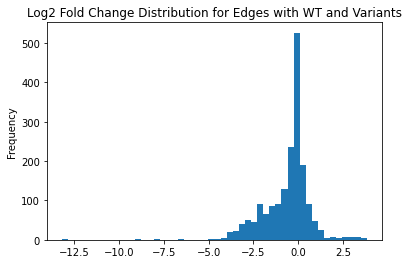

In [237]:
summed_scores_for_export_pd_pl_filtered_pd = summed_scores_for_export_pd_pl_filtered.to_pandas()

summed_scores_for_export_pd_pl_filtered_pd.log2fc.plot(kind='hist', bins=50, title='Log2 Fold Change Distribution for Edges with WT and Variants')

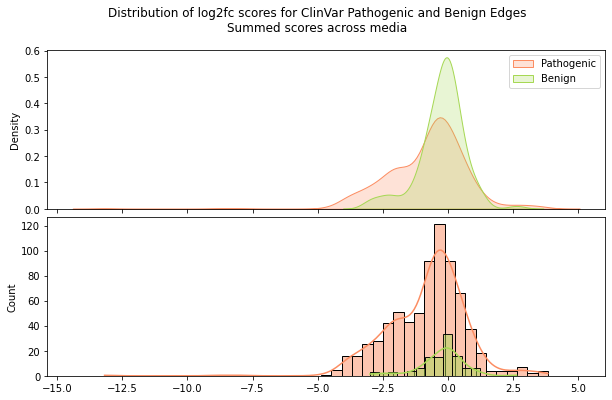

In [238]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of log2fc scores for ClinVar Pathogenic and Benign Edges\nSummed scores across media')
plt.show()

In [239]:
summed_scores = summed_scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

In [240]:
# =============================================================================
# COMPREHENSIVE FILTERING WORKFLOW TRACKING - POST-PROCESSING ANALYSIS
# =============================================================================

print("Reconstructing filtering workflow for comprehensive tracking...")
print("Note: This analysis recreates the filtering steps to track statistics")
print("="*80)

# Initialize tracking list
filtering_stats_list = []

# We need to start from before filtering and recreate the workflow
# Read the original scores before any filtering
print("Loading original scores to reconstruct filtering workflow...")

# Start by loading the original data before filtering

# Recreate the filtering workflow step by step
current_scores = scores_before_seq.clone()

# Step 0: Before any filtering (original data)
filtering_stats_list.append(get_filtering_stats(current_scores, aa_id, rrs_id, "0. Original Data"))

# Step 1: After sequence filtering (this is approximately where we start in the current workflow)
# We'll use a proxy since we can't perfectly recreate the sequence filtering
# The current 'scores' variable represents the state after sequence filtering
filtering_stats_list.append(get_filtering_stats(scores_after_seq, aa_id, rrs_id, "1. After Sequencing QC"))

# Now recreate the filtering steps that happened in the workflow
# Step 2: Autoactivation mating failures (db_group level)
aa_db_group_mating_failures = (scores_after_seq.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores_step2 = scores_after_seq.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step2, aa_id, rrs_id, "2. After AA Mating Failures (db_group)"))

# Step 3: Autoactivation technical failures
aa_db_group_tech_failures = (scores_step2.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores_step3 = scores_step2.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
# filtering_stats_list.append(get_filtering_stats(scores_step3, aa_id, rrs_id, "3. After AA Technical Failures"))

# Step 4: Mating failures - LW <= 300
mating_failures = (scores_step3.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores_step4 = scores_step3.filter(~pl.col("ppi_group").is_in(mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step4, aa_id, rrs_id, "4. After Mating Failures (LW <= 300)"))

# Step 5: Mating failures - LW null
mating_failures_2 = (scores_step4.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores_step5 = scores_step4.filter(~pl.col("ppi_group").is_in(mating_failures_2))
filtering_stats_list.append(get_filtering_stats(scores_step5, aa_id, rrs_id, "5. After Mating Failures (LW null)"))

# Step 6: Remove autoactivation rows and add AA scores
aa_scores = scores_step5.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")
)
scores_step6 = scores_step5.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
# filtering_stats_list.append(get_filtering_stats(scores_step6, aa_id, rrs_id, "6. After AA Row Removal"))

# Step 7: AA score filtering (300 threshold)
scores_step7 = scores_step6.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
filtering_stats_list.append(get_filtering_stats(scores_step7, aa_id, rrs_id, "7. After AA Score Filter (<=300)"))

# Step 8: Remove RRS pairs (keep step but don't track since numbers don't change)
scores_step8 = scores_step7.filter(pl.col('db_mut_id') != rrs_id)

# Step 9: WT failures combined (LWH1 condition + summed score filtering)
wt_failures = (scores_step8.filter(pl.col("condition_name") == "LWH1")
                    .filter(pl.col("db_mut_id") == 0)
                    .filter(pl.col("consensus_score") < 300)
                    .select("ppi_group").to_series().unique().to_list())
scores_step9 = scores_step8.filter(~pl.col("ppi_group").is_in(wt_failures))

# Additional step: Filter for summed scores where WT > 0 (this happens in summed_scores processing)
# Create summed scores to simulate the additional WT filtering
summed_temp = scores_step9.filter(pl.col("condition_name").is_in(scoring_conditions))
summed_temp = summed_temp.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

# Get WT scores for normalization
wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join and filter to only keep variants with valid WT references - MATCH THE ACTUAL LOGIC
summed_with_wt = summed_temp.join(
    wt_scores_temp, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"  # Use left join like the actual workflow
).filter(
    pl.col("wt_summed_score").is_not_null()  # Filter after join, like the actual workflow
)

# Convert back to original scores format for tracking by filtering original scores
valid_ppi_groups = summed_with_wt.with_columns(
    pl.concat_str([
        (pl.col('ad_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_mut_id').cast(pl.String) + pl.lit(".0")),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
).select("ppi_group").to_series().to_list()

scores_step10 = scores_step9.filter(pl.col("ppi_group").is_in(valid_ppi_groups))
filtering_stats_list.append(get_filtering_stats(scores_step10, aa_id, rrs_id, "8. After WT Failures + Summed Score > 0"))

# Final step: This should match our current 'scores' variable
# Note: The final filtering result should be equivalent to the current 'scores'
# Add the final state for comparison
# filtering_stats_list.append(get_filtering_stats(summed_scores, aa_id, rrs_id, "9. Final (Current State)"))

print("Filtering workflow reconstruction complete!")
print("="*80)

Reconstructing filtering workflow for comprehensive tracking...
Note: This analysis recreates the filtering steps to track statistics
Loading original scores to reconstruct filtering workflow...
Filtering workflow reconstruction complete!


In [241]:
# =============================================================================
# GENERATE COMPREHENSIVE FILTERING STATISTICS TABLE
# =============================================================================

# Create comprehensive table
print("Generating comprehensive filtering statistics table...")
comprehensive_table = create_comprehensive_filtering_table(filtering_stats_list)

# Display the table with better formatting
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("\n" + "="*120)
print("COMPREHENSIVE FILTERING STATISTICS TABLE")
print("="*120)
display(comprehensive_table)
# =============================================================================
# CREATE TWO SEPARATE SUMMARY TABLES FROM THE EXISTING COMPREHENSIVE TABLE
# =============================================================================

# 1. SUMMARY TABLE - ALL DATA (using the non-BOTH columns)
print("\n\n" + "="*120)
print("SUMMARY TABLE 1: ALL DATA (Complete Dataset)")
print("="*120)

summary_all_data = comprehensive_table[['Step', 'DB_ORF_IDs', 'AD_ORF_IDs', 'DB_Groups', 'Edge_Groups', 'PPI_Groups',
                                       'DB_ORFs_Dropped', 'AD_ORFs_Dropped', 'DB_Groups_Dropped', 'Edge_Groups_Dropped', 'PPIs_Dropped',
                                       'Percent_DB_ORFs_Dropped', 'Percent_AD_ORFs_Dropped', 'Percent_DB_Groups_Dropped', 
                                       'Percent_Edge_Groups_Dropped', 'Percent_PPIs_Dropped']].copy()

display(summary_all_data)

# 2. SUMMARY TABLE - WT+ALLELE FILTERED DATA (using the BOTH columns, renamed for clarity)
print("\n\n" + "="*120)
print("SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)")
print("="*120)

summary_wt_allele = comprehensive_table[['Step', 'DB_ORF_IDs_Both', 'AD_ORF_IDs_Both', 'DB_Groups_Both', 'Edge_Groups_Both', 'PPI_Groups_Both',
                                        'DB_ORF_IDs_Both_Dropped', 'AD_ORF_IDs_Both_Dropped', 'DB_Groups_Both_Dropped', 'Edge_Groups_Both_Dropped', 'PPI_Groups_Both_Dropped',
                                        'Percent_DB_ORF_IDs_Both_Dropped', 'Percent_AD_ORF_IDs_Both_Dropped', 'Percent_DB_Groups_Both_Dropped', 
                                        'Percent_Edge_Groups_Both_Dropped', 'Percent_PPI_Groups_Both_Dropped']].copy()

# Rename columns to make them more comprehensible (remove "_Both" suffix)
summary_wt_allele = summary_wt_allele.rename(columns={
    'DB_ORF_IDs_Both': 'DB_ORF_IDs',
    'AD_ORF_IDs_Both': 'AD_ORF_IDs',
    'DB_Groups_Both': 'DB_Groups',
    'Edge_Groups_Both': 'Edge_Groups',
    'PPI_Groups_Both': 'PPI_Groups',
    'DB_ORF_IDs_Both_Dropped': 'DB_ORFs_Dropped',
    'AD_ORF_IDs_Both_Dropped': 'AD_ORFs_Dropped',
    'DB_Groups_Both_Dropped': 'DB_Groups_Dropped',
    'Edge_Groups_Both_Dropped': 'Edge_Groups_Dropped',
    'PPI_Groups_Both_Dropped': 'PPIs_Dropped',
    'Percent_DB_ORF_IDs_Both_Dropped': 'Percent_DB_ORFs_Dropped',
    'Percent_AD_ORF_IDs_Both_Dropped': 'Percent_AD_ORFs_Dropped',
    'Percent_DB_Groups_Both_Dropped': 'Percent_DB_Groups_Dropped',
    'Percent_Edge_Groups_Both_Dropped': 'Percent_Edge_Groups_Dropped',
    'Percent_PPI_Groups_Both_Dropped': 'Percent_PPIs_Dropped'
})

display(summary_wt_allele)

# Save both tables
summary_all_data.to_csv(f"{outputs_dir}/summary_filtering_ALL_DATA.csv", index=False)
summary_wt_allele.to_csv(f"{outputs_dir}/summary_filtering_WT_ALLELE.csv", index=False)

print(f"\nTables saved:")
print(f"- Summary (All Data): {outputs_dir}/summary_filtering_ALL_DATA.csv")
print(f"- Summary (WT+Allele Filtered): {outputs_dir}/summary_filtering_WT_ALLELE.csv")

Generating comprehensive filtering statistics table...

COMPREHENSIVE FILTERING STATISTICS TABLE


,Step,Total_Rows,PPI_Groups,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,DB_ORFs_Both_WT_Variants,PPI_Groups_Both,DB_ORF_IDs_Both,AD_ORF_IDs_Both,DB_Groups_Both,Edge_Groups_Both,Rows_Dropped,PPIs_Dropped,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,DB_ORFs_Both_Dropped,PPI_Groups_Both_Dropped,DB_ORF_IDs_Both_Dropped,AD_ORF_IDs_Both_Dropped,DB_Groups_Both_Dropped,Edge_Groups_Both_Dropped,Percent_Rows_Dropped,Percent_PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_DB_ORFs_Both_Dropped,Percent_PPI_Groups_Both_Dropped,Percent_DB_ORF_IDs_Both_Dropped,Percent_AD_ORF_IDs_Both_Dropped,Percent_DB_Groups_Both_Dropped,Percent_Edge_Groups_Both_Dropped
0,0. Original Data,285965,8451,278,927,1376,1592,167,8019,167,776,1265,1160,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,193138,4583,246,783,842,1327,83,3686,83,373,669,465,92827,3868,32,144,534,265,84,4333,84,403,596,695,32.46,45.77,11.51,15.53,38.81,16.65,50.30,54.03,50.30,51.93,47.11,59.91
2,2. After AA Mating Failures (db_group),184043,4373,244,777,817,1317,81,3272,81,322,640,403,9095,210,2,6,25,10,2,414,2,51,29,62,4.71,4.58,0.81,0.77,2.97,0.75,2.41,11.23,2.41,13.67,4.33,13.33
3,4. After Mating Failures (LW <= 300),177947,4151,244,757,812,1270,81,3101,81,318,635,398,6096,222,0,20,5,47,0,171,0,4,5,5,3.31,5.08,0.00,2.57,0.61,3.57,0.00,5.23,0.00,1.24,0.78,1.24
4,5. After Mating Failures (LW null),156270,3648,232,695,781,1119,78,2730,78,304,594,380,21677,503,12,62,31,151,3,371,3,14,41,18,12.18,12.12,4.92,8.19,3.82,11.89,3.70,11.96,3.70,4.40,6.46,4.52
5,7. After AA Score Filter (<=300),84017,3636,232,695,777,1119,78,2718,78,304,590,380,72253,12,0,0,4,0,0,12,0,0,4,0,46.24,0.33,0.00,0.00,0.51,0.00,0.00,0.44,0.00,0.00,0.67,0.00
6,8. After WT Failures + Summed Score > 0,47390,2359,195,543,677,820,73,1808,73,230,555,269,36627,1277,37,152,100,299,5,910,5,74,35,111,43.59,35.12,15.95,21.87,12.87,26.72,6.41,33.48,6.41,24.34,5.93,29.21




SUMMARY TABLE 1: ALL DATA (Complete Dataset)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,278,927,1376,1592,8451,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,246,783,842,1327,4583,32,144,534,265,3868,11.51,15.53,38.81,16.65,45.77
2,2. After AA Mating Failures (db_group),244,777,817,1317,4373,2,6,25,10,210,0.81,0.77,2.97,0.75,4.58
3,4. After Mating Failures (LW <= 300),244,757,812,1270,4151,0,20,5,47,222,0.00,2.57,0.61,3.57,5.08
4,5. After Mating Failures (LW null),232,695,781,1119,3648,12,62,31,151,503,4.92,8.19,3.82,11.89,12.12
5,7. After AA Score Filter (<=300),232,695,777,1119,3636,0,0,4,0,12,0.00,0.00,0.51,0.00,0.33
6,8. After WT Failures + Summed Score > 0,195,543,677,820,2359,37,152,100,299,1277,15.95,21.87,12.87,26.72,35.12




SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,167,776,1265,1160,8019,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,83,373,669,465,3686,84,403,596,695,4333,50.30,51.93,47.11,59.91,54.03
2,2. After AA Mating Failures (db_group),81,322,640,403,3272,2,51,29,62,414,2.41,13.67,4.33,13.33,11.23
3,4. After Mating Failures (LW <= 300),81,318,635,398,3101,0,4,5,5,171,0.00,1.24,0.78,1.24,5.23
4,5. After Mating Failures (LW null),78,304,594,380,2730,3,14,41,18,371,3.70,4.40,6.46,4.52,11.96
5,7. After AA Score Filter (<=300),78,304,590,380,2718,0,0,4,0,12,0.00,0.00,0.67,0.00,0.44
6,8. After WT Failures + Summed Score > 0,73,230,555,269,1808,5,74,35,111,910,6.41,24.34,5.93,29.21,33.48



Tables saved:
- Summary (All Data): ../3_outputs/sqY2H/summary_filtering_ALL_DATA.csv
- Summary (WT+Allele Filtered): ../3_outputs/sqY2H/summary_filtering_WT_ALLELE.csv


## best media instead of summing

In [242]:
# Finding maximum perturbation scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

perturbation_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# Get WT scores for each condition
wt_scores = perturbation_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "condition_name", "consensus_score"
]).rename({"consensus_score": "wt_score"})

# Join variant scores with their corresponding WT scores for each condition
perturbation_scores = perturbation_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch", "condition_name"], 
    how="left"
).filter(
    pl.col("wt_score").is_not_null()  # Only keep variants that have a WT reference
)

# Calculate score difference for each condition
perturbation_scores = perturbation_scores.with_columns(
    (pl.col("wt_score") - pl.col("consensus_score")).alias("score_difference"),
    ((pl.col("consensus_score") + 1) / (pl.col("wt_score") + 1)).alias("fold_change"),
    ((pl.col("consensus_score") + 1) / (pl.col("wt_score") + 1)).log().alias("log2_fold_change") / np.log(2)
)

# Add a within-group row number to match with arg_max
perturbation_scores = perturbation_scores.with_columns(
    pl.int_range(pl.len()).over(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch']).alias("group_row_nr")
)

# For each variant, find the condition with maximum perturbation (absolute difference)
max_perturbation_idx = perturbation_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("score_difference").abs().arg_max().alias("max_perturbation_idx")
])

# Join back to get the actual condition information
max_perturbation_with_condition = max_perturbation_idx.join(
    perturbation_scores,
    left_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "max_perturbation_idx"],
    right_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "group_row_nr"],
    how="left"
).select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch",
    "condition_name", "consensus_score", "wt_score", 
    "score_difference", "fold_change", "log2_fold_change"
]).rename({
    "condition_name": "max_perturbation_condition",
    "consensus_score": "max_perturbation_variant_score", 
    "wt_score": "max_perturbation_wt_score",
    "score_difference": "max_perturbation",
    "fold_change": "max_perturbation_fold",
    "log2_fold_change": "max_log2_fold_change"
})

# Also calculate the summary statistics
max_perturbation_stats = perturbation_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("score_difference").abs().max().alias("max_perturbation_abs"),
    pl.col("fold_change").abs().max().alias("max_perturbation_fold_abs")
])

# Combine everything
max_perturbation_final = max_perturbation_with_condition.join(
    max_perturbation_stats,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Max perturbation scores shape: {max_perturbation_final.shape}")
max_perturbation_final

Max perturbation scores shape: (2359, 12)


ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64
52634,5673,0,"""VUSAPWT6B1""","""LWA""",51.614053,51.614053,0.0,1.0,0.0,0.0,1.0
2500,2713,200818,"""VUSAPWT1B1""","""LWH10""",0.0,500.480402,500.480402,0.001994,-8.97005,500.480402,1.0
13662,5066,201832,"""VUSAPWT1B2""","""LWH25""",68.008824,162.474185,94.465361,0.422139,-1.24421,94.465361,1.0
53281,55246,3221,"""VUSAPWT1B1""","""LWH10""",223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756
824,2448,0,"""VUSAPWT1B2""","""LWA""",360.368636,360.368636,0.0,1.0,0.0,0.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…
53025,3180,214556,"""VUSAPWT1B2""","""LWH10""",602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466
10064,52920,2670,"""VUSAPWT2B1""","""LWA""",358.170267,533.974199,175.803932,0.671379,-0.574801,175.803932,1.155485
487,3535,0,"""VUSAPWT6B1""","""LWA""",571.349698,571.349698,0.0,1.0,0.0,0.0,1.0


In [243]:
max_perturbation_final = max_perturbation_final.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
max_perturbation_final

ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
52634,5673,0,"""VUSAPWT6B1""","""LWA""",51.614053,51.614053,0.0,1.0,0.0,0.0,1.0,"""PLN""",null,null,"""ENSG00000198523""",null,null,null,null,"""PLN"""
2500,2713,200818,"""VUSAPWT1B1""","""LWH10""",0.0,500.480402,500.480402,0.001994,-8.97005,500.480402,1.0,"""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""
13662,5066,201832,"""VUSAPWT1B2""","""LWH25""",68.008824,162.474185,94.465361,0.422139,-1.24421,94.465361,1.0,"""BAG3""","""Pro380Ser""","""1138C>T""","""ENSG00000151929""","""CEGS2""","""2_Benign""",0.000499,2.0,"""BAG3_Pro380Ser"""
53281,55246,3221,"""VUSAPWT1B1""","""LWH10""",223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,"""PYGL""","""Val456Met""","""1366G>A""","""ENSG00000100504""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""PYGL_Val456Met"""
824,2448,0,"""VUSAPWT1B2""","""LWA""",360.368636,360.368636,0.0,1.0,0.0,0.0,1.0,"""GRN""",null,null,"""ENSG00000030582""",null,null,null,null,"""GRN"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
53025,3180,214556,"""VUSAPWT1B2""","""LWH10""",602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,"""NAA10""","""Arg116Trp""","""346C>T""","""ENSG00000102030""","""CEGS2""","""1_Pathogenic""",null,2.0,"""NAA10_Arg116Trp"""
10064,52920,2670,"""VUSAPWT2B1""","""LWA""",358.170267,533.974199,175.803932,0.671379,-0.574801,175.803932,1.155485,"""LITAF""","""Gly130Ser""","""388G>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Gly130Ser"""
487,3535,0,"""VUSAPWT6B1""","""LWA""",571.349698,571.349698,0.0,1.0,0.0,0.0,1.0,"""EMD""",null,null,"""ENSG00000102119""",null,null,null,null,"""EMD"""


In [244]:
max_perturbation_final_pd = max_perturbation_final.to_pandas()
max_perturbation_final_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,52634,5673,0,VUSAPWT6B1,LWA,51.614053,51.614053,0.000000,1.000000,0.000000,0.000000,1.000000,PLN,None,None,ENSG00000198523,None,None,NaN,NaN,PLN
1,2500,2713,200818,VUSAPWT1B1,LWH10,0.000000,500.480402,500.480402,0.001994,-8.970050,500.480402,1.000000,MLH1,Leu73Arg,218T>G,ENSG00000076242,CEGS2,1_Pathogenic,NaN,2.0,MLH1_Leu73Arg
2,13662,5066,201832,VUSAPWT1B2,LWH25,68.008824,162.474185,94.465361,0.422139,-1.244210,94.465361,1.000000,BAG3,Pro380Ser,1138C>T,ENSG00000151929,CEGS2,2_Benign,0.000499,2.0,BAG3_Pro380Ser
3,53281,55246,3221,VUSAPWT1B1,LWH10,223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,PYGL,Val456Met,1366G>A,ENSG00000100504,Edgotyping3,1_Pathogenic,NaN,2.0,PYGL_Val456Met
4,824,2448,0,VUSAPWT1B2,LWA,360.368636,360.368636,0.000000,1.000000,0.000000,0.000000,1.000000,GRN,None,None,ENSG00000030582,None,None,NaN,NaN,GRN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2354,53025,3180,214556,VUSAPWT1B2,LWH10,602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,NAA10,Arg116Trp,346C>T,ENSG00000102030,CEGS2,1_Pathogenic,NaN,2.0,NAA10_Arg116Trp
2355,10064,52920,2670,VUSAPWT2B1,LWA,358.170267,533.974199,175.803932,0.671379,-0.574801,175.803932,1.155485,LITAF,Gly130Ser,388G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Gly130Ser
2356,487,3535,0,VUSAPWT6B1,LWA,571.349698,571.349698,0.000000,1.000000,0.000000,0.000000,1.000000,EMD,None,None,ENSG00000102119,None,None,NaN,NaN,EMD
2357,6520,9866,0,VUSAPWT1B2,LWA,8.180719,8.180719,0.000000,1.000000,0.000000,0.000000,1.000000,ZMYND10,None,None,ENSG00000004838,None,None,NaN,NaN,ZMYND10


In [245]:
print(f"Original max_perturbation_final shape: {max_perturbation_final.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final.select(pl.col('ad_orf_id').n_unique()).item()}")

Original max_perturbation_final shape: (2359, 21)
Filtered max_perturbation_final db orfs: 195
Filtered max_perturbation_final ad orfs: 543


In [246]:

# Filter for edges that have both WT and at least one variant

# Find edges (ad_orf_id, db_orf_id, retest_batch) with WT data
edges_with_wt = max_perturbation_final.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Find edges with variant data  
edges_with_variants = max_perturbation_final.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Get intersection - edges that have both WT and variants
edges_with_both = edges_with_wt.join(
    edges_with_variants, 
    on=["db_orf_id"],#, "ad_orf_id", "retest_batch"], 
    how="inner"
)

# Filter max_perturbation_final to only include these edges
max_perturbation_final_filtered = max_perturbation_final.join(
    edges_with_both,
    on=["db_orf_id"],# "ad_orf_id", "retest_batch"],
    how="inner"
)

print(f"Original max_perturbation_final shape: {max_perturbation_final.shape}")
print(f"Filtered max_perturbation_final shape: {max_perturbation_final_filtered.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final_filtered.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final_filtered.select(pl.col('ad_orf_id').n_unique()).item()}")
print(f"Unique edges with both WT and variants: {edges_with_both.height}")

# Remove WT rows (db_mut_id == 0) to keep only variants
max_perturbation_final_filtered = max_perturbation_final_filtered.filter(pl.col("db_mut_id") != 0)

print(f"After removing WT rows: {max_perturbation_final_filtered.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final_filtered.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final_filtered.select(pl.col('ad_orf_id').n_unique()).item()}")
print(f"Unique edges with both WT and variants: {edges_with_both.height}")

max_perturbation_final_filtered_pd = max_perturbation_final_filtered.to_pandas()
max_perturbation_final_filtered

Original max_perturbation_final shape: (2359, 21)
Filtered max_perturbation_final shape: (1808, 21)
Filtered max_perturbation_final db orfs: 73
Filtered max_perturbation_final ad orfs: 230
Unique edges with both WT and variants: 73
After removing WT rows: (1539, 21)
Filtered max_perturbation_final db orfs: 73
Filtered max_perturbation_final ad orfs: 225
Unique edges with both WT and variants: 73


ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
2500,2713,200818,"""VUSAPWT1B1""","""LWH10""",0.0,500.480402,500.480402,0.001994,-8.97005,500.480402,1.0,"""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""
13662,5066,201832,"""VUSAPWT1B2""","""LWH25""",68.008824,162.474185,94.465361,0.422139,-1.24421,94.465361,1.0,"""BAG3""","""Pro380Ser""","""1138C>T""","""ENSG00000151929""","""CEGS2""","""2_Benign""",0.000499,2.0,"""BAG3_Pro380Ser"""
53281,55246,3221,"""VUSAPWT1B1""","""LWH10""",223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,"""PYGL""","""Val456Met""","""1366G>A""","""ENSG00000100504""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""PYGL_Val456Met"""
55664,4870,215295,"""VUSAPWT1B2""","""LWA""",231.80164,487.978113,256.176473,0.476098,-1.070669,256.176473,0.731553,"""KRT6A""","""Glu461Lys""","""1381G>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Glu461Lys"""
54326,7323,216370,"""VUSAPWT1B1""","""LWH25""",297.694122,188.741179,-108.952943,1.574219,0.654636,108.952943,1.574219,"""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6490,71077,220314,"""VUSAPWT2B1""","""LWA""",104.616995,216.657193,112.040198,0.485245,-1.043216,112.040198,1.288982,"""IMPDH1""","""Val317Ile""","""949G>A""","""ENSG00000106348""","""RC4""","""4_VUS""",null,1.0,"""IMPDH1_Val317Ile"""
2920,2920,214445,"""VUSAPWT1B2""","""LWH1""",229.631814,301.441512,71.809698,0.762567,-0.391065,71.809698,1.701445,"""GFAP""","""Glu371Val""","""1112A>T""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu371Val"""
53025,3180,214556,"""VUSAPWT1B2""","""LWH10""",602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,"""NAA10""","""Arg116Trp""","""346C>T""","""ENSG00000102030""","""CEGS2""","""1_Pathogenic""",null,2.0,"""NAA10_Arg116Trp"""


In [247]:
max_perturbation_final_filtered_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,2500,2713,200818,VUSAPWT1B1,LWH10,0.000000,500.480402,500.480402,0.001994,-8.970050,500.480402,1.000000,MLH1,Leu73Arg,218T>G,ENSG00000076242,CEGS2,1_Pathogenic,NaN,2.0,MLH1_Leu73Arg
1,13662,5066,201832,VUSAPWT1B2,LWH25,68.008824,162.474185,94.465361,0.422139,-1.244210,94.465361,1.000000,BAG3,Pro380Ser,1138C>T,ENSG00000151929,CEGS2,2_Benign,0.000499,2.0,BAG3_Pro380Ser
2,53281,55246,3221,VUSAPWT1B1,LWH10,223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,PYGL,Val456Met,1366G>A,ENSG00000100504,Edgotyping3,1_Pathogenic,NaN,2.0,PYGL_Val456Met
3,55664,4870,215295,VUSAPWT1B2,LWA,231.801640,487.978113,256.176473,0.476098,-1.070669,256.176473,0.731553,KRT6A,Glu461Lys,1381G>A,ENSG00000205420,CEGS2,1_Pathogenic,NaN,1.0,KRT6A_Glu461Lys
4,54326,7323,216370,VUSAPWT1B1,LWH25,297.694122,188.741179,-108.952943,1.574219,0.654636,108.952943,1.574219,PMP22,Gly150Cys,448G>T,ENSG00000109099,CEGS2,3_Conflicting,NaN,1.0,PMP22_Gly150Cys
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,6490,71077,220314,VUSAPWT2B1,LWA,104.616995,216.657193,112.040198,0.485245,-1.043216,112.040198,1.288982,IMPDH1,Val317Ile,949G>A,ENSG00000106348,RC4,4_VUS,NaN,1.0,IMPDH1_Val317Ile
1535,2920,2920,214445,VUSAPWT1B2,LWH1,229.631814,301.441512,71.809698,0.762567,-0.391065,71.809698,1.701445,GFAP,Glu371Val,1112A>T,ENSG00000131095,CEGS2,5_Others,NaN,NaN,GFAP_Glu371Val
1536,53025,3180,214556,VUSAPWT1B2,LWH10,602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,NAA10,Arg116Trp,346C>T,ENSG00000102030,CEGS2,1_Pathogenic,NaN,2.0,NAA10_Arg116Trp
1537,10064,52920,2670,VUSAPWT2B1,LWA,358.170267,533.974199,175.803932,0.671379,-0.574801,175.803932,1.155485,LITAF,Gly130Ser,388G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Gly130Ser


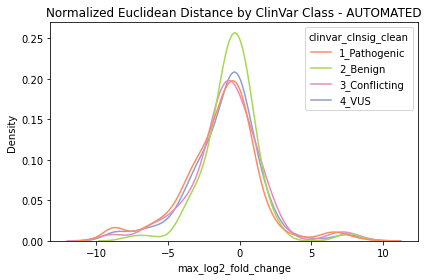

In [248]:
variables = ["max_log2_fold_change", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=max_perturbation_final_filtered,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

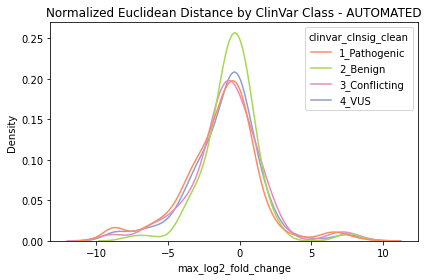

In [249]:
max_perturbation_final_filtered_log2_filtered = max_perturbation_final_filtered.filter(
    (pl.col("max_log2_fold_change") > -25) & (pl.col("max_log2_fold_change") < 25)
)

variables = ["max_log2_fold_change", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=max_perturbation_final_filtered_log2_filtered,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

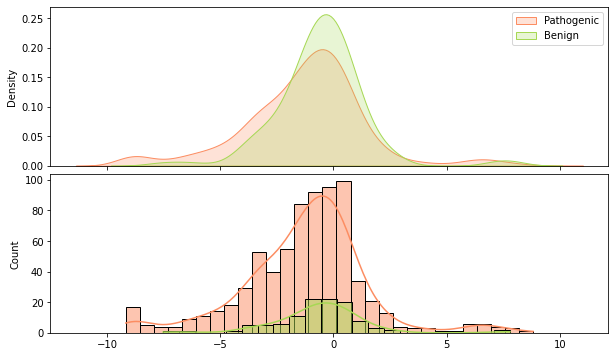

In [250]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

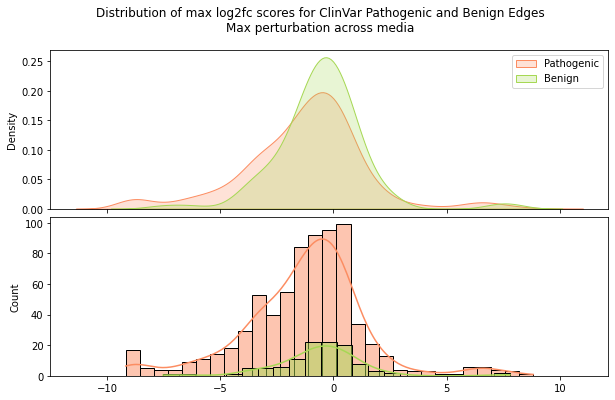

In [251]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of max log2fc scores for ClinVar Pathogenic and Benign Edges\nMax perturbation across media')
plt.show()

In [253]:
max_perturbation_final_filtered

ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
2500,2713,200818,"""VUSAPWT1B1""","""LWH10""",0.0,500.480402,500.480402,0.001994,-8.97005,500.480402,1.0,"""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""
13662,5066,201832,"""VUSAPWT1B2""","""LWH25""",68.008824,162.474185,94.465361,0.422139,-1.24421,94.465361,1.0,"""BAG3""","""Pro380Ser""","""1138C>T""","""ENSG00000151929""","""CEGS2""","""2_Benign""",0.000499,2.0,"""BAG3_Pro380Ser"""
53281,55246,3221,"""VUSAPWT1B1""","""LWH10""",223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,"""PYGL""","""Val456Met""","""1366G>A""","""ENSG00000100504""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""PYGL_Val456Met"""
55664,4870,215295,"""VUSAPWT1B2""","""LWA""",231.80164,487.978113,256.176473,0.476098,-1.070669,256.176473,0.731553,"""KRT6A""","""Glu461Lys""","""1381G>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Glu461Lys"""
54326,7323,216370,"""VUSAPWT1B1""","""LWH25""",297.694122,188.741179,-108.952943,1.574219,0.654636,108.952943,1.574219,"""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6490,71077,220314,"""VUSAPWT2B1""","""LWA""",104.616995,216.657193,112.040198,0.485245,-1.043216,112.040198,1.288982,"""IMPDH1""","""Val317Ile""","""949G>A""","""ENSG00000106348""","""RC4""","""4_VUS""",null,1.0,"""IMPDH1_Val317Ile"""
2920,2920,214445,"""VUSAPWT1B2""","""LWH1""",229.631814,301.441512,71.809698,0.762567,-0.391065,71.809698,1.701445,"""GFAP""","""Glu371Val""","""1112A>T""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Glu371Val"""
53025,3180,214556,"""VUSAPWT1B2""","""LWH10""",602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,"""NAA10""","""Arg116Trp""","""346C>T""","""ENSG00000102030""","""CEGS2""","""1_Pathogenic""",null,2.0,"""NAA10_Arg116Trp"""


In [254]:
# Finding maximum perturbation scores for MANUAL scoring (using adjusted_score)

# Keep a reference to original data with condition names for manual scoring
original_conditions_manual = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

# Get the scores data for manual scoring analysis (using adjusted_score from the QA/QC pipeline)
perturbation_scores_manual = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# Use the manual_score_growth that's already in the scores dataframe
# Get WT manual scores for each condition
wt_scores_manual = perturbation_scores_manual.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "condition_name", "manual_score_growth"
]).rename({"manual_score_growth": "wt_manual_score"})

# Join variant scores with their corresponding WT scores for each condition
perturbation_scores_manual = perturbation_scores_manual.join(
    wt_scores_manual, 
    on=["ad_orf_id", "db_orf_id", "retest_batch", "condition_name"], 
    how="left"
).filter(
    pl.col("wt_manual_score").is_not_null()  # Only keep variants that have a WT reference
)

# Calculate score difference for each condition using manual scores
perturbation_scores_manual = perturbation_scores_manual.with_columns(
    (pl.col("wt_manual_score") - pl.col("manual_score_growth")).alias("manual_score_difference"),
    ((pl.col("manual_score_growth") + 0.1) / (pl.col("wt_manual_score") + 1e-8)).alias("manual_fold_change"),
    ((pl.col("manual_score_growth") + 0.1) / (pl.col("wt_manual_score") + 1e-8)).log().alias("manual_log2_fold_change") / np.log(2)
)

# Add a within-group row number to match with arg_max
perturbation_scores_manual = perturbation_scores_manual.with_columns(
    pl.int_range(pl.len()).over(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch']).alias("group_row_nr_manual")
)

# For each variant, find the condition with maximum perturbation (absolute difference) for manual scores
max_perturbation_idx_manual = perturbation_scores_manual.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("manual_score_difference").abs().arg_max().alias("max_perturbation_idx_manual")
])

# Join back to get the actual condition information for manual scores
max_perturbation_with_condition_manual = max_perturbation_idx_manual.join(
    perturbation_scores_manual,
    left_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "max_perturbation_idx_manual"],
    right_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "group_row_nr_manual"],
    how="left"
).select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch",
    "condition_name", "manual_score_growth", "wt_manual_score", 
    "manual_score_difference", "manual_fold_change", "manual_log2_fold_change"
]).rename({
    "condition_name": "max_perturbation_condition_manual",
    "manual_score_growth": "max_perturbation_variant_manual_score", 
    "wt_manual_score": "max_perturbation_wt_manual_score",
    "manual_score_difference": "max_perturbation_manual",
    "manual_fold_change": "max_perturbation_manual_fold",
    "manual_log2_fold_change": "max_manual_log2_fold_change"
})

# Also calculate the summary statistics for manual scores
max_perturbation_stats_manual = perturbation_scores_manual.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("manual_score_difference").abs().max().alias("max_perturbation_manual_abs"),
    pl.col("manual_fold_change").abs().max().alias("max_perturbation_manual_fold_abs")
])

# Combine everything for manual scores
max_perturbation_final_manual = max_perturbation_with_condition_manual.join(
    max_perturbation_stats_manual,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Max perturbation manual scores shape: {max_perturbation_final_manual.shape}")

# Add metadata to manual results
max_perturbation_final_manual = max_perturbation_final_manual.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Filter for edges that have both WT and at least one variant (same logic as automated)
edges_with_wt_manual = max_perturbation_final_manual.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"
]).unique()

edges_with_variants_manual = max_perturbation_final_manual.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"
]).unique()

edges_with_both_manual = edges_with_wt_manual.join(
    edges_with_variants_manual, 
    on=["db_orf_id"], 
    how="inner"
)

# Filter max_perturbation_final_manual to only include these edges
max_perturbation_final_filtered_manual = max_perturbation_final_manual.join(
    edges_with_both_manual,
    on=["db_orf_id"],
    how="inner"
)

# Remove WT rows (db_mut_id == 0) to keep only variants
max_perturbation_final_filtered_manual = max_perturbation_final_filtered_manual.filter(pl.col("db_mut_id") != 0)

print(f"Max perturbation manual scores filtered shape: {max_perturbation_final_filtered_manual.shape}")
print(f"Manual filtered db orfs: {max_perturbation_final_filtered_manual.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Manual filtered ad orfs: {max_perturbation_final_filtered_manual.select(pl.col('ad_orf_id').n_unique()).item()}")

# Now merge the manual results with the automated results
# Convert both to pandas for easier merging
max_perturbation_final_filtered_pd = max_perturbation_final_filtered.to_pandas()
max_perturbation_final_filtered_manual_pd = max_perturbation_final_filtered_manual.to_pandas()

# Merge on the key columns to combine automated and manual results
combined_results = max_perturbation_final_filtered_pd.merge(
    max_perturbation_final_filtered_manual_pd[["db_orf_id", "ad_orf_id", "db_mut_id", "retest_batch", 
                                               "max_perturbation_condition_manual", "max_perturbation_variant_manual_score",
                                               "max_perturbation_wt_manual_score", "max_perturbation_manual",
                                               "max_perturbation_manual_fold", "max_manual_log2_fold_change",
                                               "max_perturbation_manual_abs", "max_perturbation_manual_fold_abs"]],
    on=["db_orf_id", "ad_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Combined results shape: {combined_results.shape}")
combined_results

Max perturbation manual scores shape: (2359, 12)
Max perturbation manual scores filtered shape: (1539, 21)
Manual filtered db orfs: 73
Manual filtered ad orfs: 225
Combined results shape: (1539, 29)


,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,max_perturbation_condition_manual,max_perturbation_variant_manual_score,max_perturbation_wt_manual_score,max_perturbation_manual,max_perturbation_manual_fold,max_manual_log2_fold_change,max_perturbation_manual_abs,max_perturbation_manual_fold_abs
0,2500,2713,200818,VUSAPWT1B1,LWH10,0.000000,500.480402,500.480402,0.001994,-8.970050,500.480402,1.000000,MLH1,Leu73Arg,218T>G,ENSG00000076242,CEGS2,1_Pathogenic,NaN,2.0,MLH1_Leu73Arg,LWH1,0.0,4.0,4.0,2.500000e-02,-5.321928,4.0,1.000000e-01
1,13662,5066,201832,VUSAPWT1B2,LWH25,68.008824,162.474185,94.465361,0.422139,-1.244210,94.465361,1.000000,BAG3,Pro380Ser,1138C>T,ENSG00000151929,CEGS2,2_Benign,0.000499,2.0,BAG3_Pro380Ser,LWH10,0.0,2.0,2.0,5.000000e-02,-4.321928,2.0,1.000000e+07
2,53281,55246,3221,VUSAPWT1B1,LWH10,223.082362,614.400027,391.317665,0.364125,-1.457495,391.317665,1.300756,PYGL,Val456Met,1366G>A,ENSG00000100504,Edgotyping3,1_Pathogenic,NaN,2.0,PYGL_Val456Met,LWA,2.0,4.0,2.0,5.250000e-01,-0.929611,2.0,1.025000e+00
3,55664,4870,215295,VUSAPWT1B2,LWA,231.801640,487.978113,256.176473,0.476098,-1.070669,256.176473,0.731553,KRT6A,Glu461Lys,1381G>A,ENSG00000205420,CEGS2,1_Pathogenic,NaN,1.0,KRT6A_Glu461Lys,LWA,3.0,3.0,0.0,1.033333e+00,0.047306,0.0,1.050000e+00
4,54326,7323,216370,VUSAPWT1B1,LWH25,297.694122,188.741179,-108.952943,1.574219,0.654636,108.952943,1.574219,PMP22,Gly150Cys,448G>T,ENSG00000109099,CEGS2,3_Conflicting,NaN,1.0,PMP22_Gly150Cys,LWA,0.0,0.0,0.0,1.000000e+07,23.253497,0.0,1.000000e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,6490,71077,220314,VUSAPWT2B1,LWA,104.616995,216.657193,112.040198,0.485245,-1.043216,112.040198,1.288982,IMPDH1,Val317Ile,949G>A,ENSG00000106348,RC4,4_VUS,NaN,1.0,IMPDH1_Val317Ile,LWA,2.0,2.0,0.0,1.050000e+00,0.070389,0.0,1.050000e+00
1535,2920,2920,214445,VUSAPWT1B2,LWH1,229.631814,301.441512,71.809698,0.762567,-0.391065,71.809698,1.701445,GFAP,Glu371Val,1112A>T,ENSG00000131095,CEGS2,5_Others,NaN,NaN,GFAP_Glu371Val,LWH1,2.0,3.0,1.0,7.000000e-01,-0.514573,1.0,1.050000e+00
1536,53025,3180,214556,VUSAPWT1B2,LWH10,602.217999,491.423222,-110.794778,1.224999,0.292781,110.794778,2.300466,NAA10,Arg116Trp,346C>T,ENSG00000102030,CEGS2,1_Pathogenic,NaN,2.0,NAA10_Arg116Trp,LWH10,4.0,3.0,-1.0,1.366667e+00,0.450661,1.0,1.550000e+00
1537,10064,52920,2670,VUSAPWT2B1,LWA,358.170267,533.974199,175.803932,0.671379,-0.574801,175.803932,1.155485,LITAF,Gly130Ser,388G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Gly130Ser,LWA,3.0,4.0,1.0,7.750000e-01,-0.367732,1.0,1.050000e+00


In [255]:
perturbation_scores_manual_pd = perturbation_scores_manual.to_pandas()

perturbation_scores_manual_pd[
    (perturbation_scores_manual_pd.db_orf_id == 14221) &
    (perturbation_scores_manual_pd.db_mut_id == 218281) &
    (perturbation_scores_manual_pd.condition_name == "LWH25") &
    (perturbation_scores_manual_pd.ad_orf_id == 14221)
]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,wt_manual_score,manual_score_difference,manual_fold_change,manual_log2_fold_change,group_row_nr_manual
74612,VUSAPWT1B2r05_028,O13,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,495.143803,False,9.090493,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,48
74613,VUSAPWT1B2r05_028,O13,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,495.143803,False,9.090493,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,49
74614,VUSAPWT1B2r05_028,O13,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,495.143803,False,9.090493,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,50
74615,VUSAPWT1B2r05_028,O13,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,495.143803,False,9.090493,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,51
74616,VUSAPWT1B2r05_028,O14,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,524.763406,False,9.166824,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,52
74617,VUSAPWT1B2r05_028,O14,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,524.763406,False,9.166824,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,53
74618,VUSAPWT1B2r05_028,O14,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,524.763406,False,9.166824,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,0.0,-4.0,410000000.0,28.611049,54
74619,VUSAPWT1B2r05_028,O14,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,524.763406,False,9.166824,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,1422

In [256]:
np.log2(0.1 / 3)

-4.906890595608519

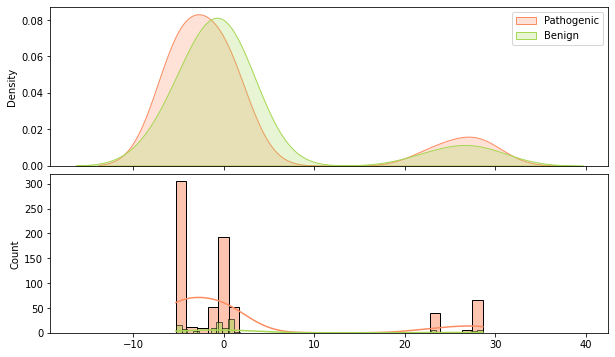

In [257]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_manual_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_manual_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_manual_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_manual_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

## dropped orfs

In [258]:
# ...existing code...

def track_db_orf_id_filtering(target_db_orf_id, scores_before_seq=scores_before_seq, aa_id=aa_id, rrs_id=rrs_id, scoring_conditions=scoring_conditions):
    """
    Track where a specific db_orf_id gets dropped during the QA/QC filtering workflow
    
    Parameters:
    target_db_orf_id: The db_orf_id to track
    scores_before_seq: The initial scores dataframe before sequence filtering
    aa_id: autoactivation ID
    rrs_id: RRS ID
    scoring_conditions: list of scoring conditions
    
    Returns:
    dict: Summary of where the db_orf_id was present/dropped
    """
    
    tracking_results = {
        'db_orf_id': target_db_orf_id,
        'steps': [],
        'dropped_at_step': None,
        'final_status': 'Unknown'
    }
    
    def check_presence(df, step_name):
        """Check if target_db_orf_id is present in the dataframe"""
        present = df.filter(pl.col("db_orf_id") == target_db_orf_id).height > 0
        if present:
            count = df.filter(pl.col("db_orf_id") == target_db_orf_id).height
            unique_variants = df.filter(pl.col("db_orf_id") == target_db_orf_id).select("db_mut_id").n_unique()
            unique_ads = df.filter(pl.col("db_orf_id") == target_db_orf_id).select("ad_orf_id").n_unique()
            
            # Get sample of the data
            sample_data = df.filter(pl.col("db_orf_id") == target_db_orf_id).head(3).select([
                "ad_orf_id", "db_mut_id", "condition_name", "consensus_score", "retest_batch"
            ]).to_pandas()
            
            return {
                'present': True,
                'total_rows': count,
                'unique_variants': unique_variants,
                'unique_ads': unique_ads,
                'sample_data': sample_data.to_dict('records') if len(sample_data) > 0 else []
            }
        else:
            return {'present': False, 'total_rows': 0, 'unique_variants': 0, 'unique_ads': 0, 'sample_data': []}
    
    print(f"Tracking db_orf_id {target_db_orf_id} through QA/QC filtering workflow...")
    print("="*80)
    
    # Step 0: Original data
    current_scores = scores_before_seq.clone()
    step_info = check_presence(current_scores, "0. Original Data")
    step_info['step_name'] = "0. Original Data"
    tracking_results['steps'].append(step_info)
    print(f"Step 0 - Original Data: {'✓ Present' if step_info['present'] else '✗ Not Present'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "0. Original Data (Never present)"
        tracking_results['final_status'] = 'Never present in original data'
        return tracking_results
    
    # Step 1: After sequence filtering (approximated by scores_after_seq if available)
    try:
        # Try to use the actual scores_after_seq from the workflow
        step_info = check_presence(scores_after_seq, "1. After Sequencing QC")
        step_info['step_name'] = "1. After Sequencing QC"
        tracking_results['steps'].append(step_info)
        print(f"Step 1 - After Sequencing QC: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "1. After Sequencing QC"
            tracking_results['final_status'] = 'Dropped during sequence confirmation filtering'
            return tracking_results
        
        current_scores = scores_after_seq.clone()
    except NameError:
        print("Warning: scores_after_seq not available, using current_scores")
    
    # Step 2: AA mating failures (db_group level)
    aa_db_group_mating_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                  .filter(pl.col("condition_name") == "LW")
                                  .filter(pl.col("consensus_score") <= 300)
                                  .select("db_group")
                                  .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    
    step_info = check_presence(current_scores, "2. After AA Mating Failures (db_group)")
    step_info['step_name'] = "2. After AA Mating Failures (db_group)"
    step_info['aa_failures_removed'] = len(aa_db_group_mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 2 - After AA Mating Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "2. After AA Mating Failures (db_group)"
        tracking_results['final_status'] = 'Dropped due to autoactivation mating failures'
        return tracking_results
    
    # Step 3: AA technical failures
    aa_db_group_tech_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                       .filter(pl.col("consensus_score").is_nan())
                                       .select("db_condition_group")
                                       .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    
    step_info = check_presence(current_scores, "3. After AA Technical Failures")
    step_info['step_name'] = "3. After AA Technical Failures"
    tracking_results['steps'].append(step_info)
    print(f"Step 3 - After AA Technical Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "3. After AA Technical Failures"
        tracking_results['final_status'] = 'Dropped due to autoactivation technical failures'
        return tracking_results
    
    # Step 4: Mating failures - LW <= 300
    mating_failures = (current_scores.filter(pl.col("condition_name") == "LW")
                             .filter(pl.col("consensus_score") <= 300)
                             .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    
    step_info = check_presence(current_scores, "4. After Mating Failures (LW <= 300)")
    step_info['step_name'] = "4. After Mating Failures (LW <= 300)"
    step_info['mating_failures_removed'] = len(mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 4 - After Mating Failures (LW <= 300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "4. After Mating Failures (LW <= 300)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score <= 300)'
        return tracking_results
    
    # Step 5: Mating failures - LW null
    mating_failures_2 = (current_scores.filter(pl.col("condition_name") == "LW")
                               .filter(pl.col("consensus_score").is_null())
                               .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))
    
    step_info = check_presence(current_scores, "5. After Mating Failures (LW null)")
    step_info['step_name'] = "5. After Mating Failures (LW null)"
    tracking_results['steps'].append(step_info)
    print(f"Step 5 - After Mating Failures (LW null): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "5. After Mating Failures (LW null)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score null)'
        return tracking_results
    
    # Step 6: Remove autoactivation rows and add AA scores
    aa_scores = current_scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")
    )
    current_scores = current_scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
    
    step_info = check_presence(current_scores, "6. After AA Row Removal")
    step_info['step_name'] = "6. After AA Row Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 6 - After AA Row Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "6. After AA Row Removal"
        tracking_results['final_status'] = 'Was only present as autoactivation rows'
        return tracking_results
    
    # Step 7: AA score filtering (300 threshold)
    current_scores = current_scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
    
    step_info = check_presence(current_scores, "7. After AA Score Filter (<=300)")
    step_info['step_name'] = "7. After AA Score Filter (<=300)"
    tracking_results['steps'].append(step_info)
    print(f"Step 7 - After AA Score Filter (<=300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "7. After AA Score Filter (<=300)"
        tracking_results['final_status'] = 'Dropped due to high autoactivation score (>300)'
        return tracking_results
    
    # Step 8: Remove RRS pairs
    current_scores = current_scores.filter(pl.col('db_mut_id') != rrs_id)
    
    step_info = check_presence(current_scores, "8. After RRS Removal")
    step_info['step_name'] = "8. After RRS Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 8 - After RRS Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "8. After RRS Removal"
        tracking_results['final_status'] = 'Was only present as RRS pairs'
        return tracking_results
    
    # Step 9: WT failures (LWH1 condition)
    wt_failures = (current_scores.filter(pl.col("condition_name") == "LWH1")
                        .filter(pl.col("db_mut_id") == 0)
                        .filter(pl.col("consensus_score") < 300)
                        .select("edge_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
    step_info = check_presence(current_scores, "9. After WT Failures (LWH1 < 300)")
    step_info['step_name'] = "9. After WT Failures (LWH1 < 300)"
    step_info['wt_failures_removed'] = len(wt_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 9 - After WT Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "9. After WT Failures (LWH1 < 300)"
        tracking_results['final_status'] = 'Dropped due to WT failure in LWH1 condition'
        return tracking_results
    
    # Step 10: Final summed score filtering (simulated)
    try:
        # Simulate the summed score filtering logic
        summed_temp = current_scores.filter(pl.col("condition_name").is_in(scoring_conditions))
        summed_temp = summed_temp.group_by([
            'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
        ]).agg(
            pl.col("consensus_score").sum().alias("summed_consensus_score")
        )
        
        # Get WT scores for normalization
        wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
            "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
        ]).rename({"summed_consensus_score": "wt_summed_score"})
        
        # Join and filter to only keep variants with valid WT references
        summed_with_wt = summed_temp.join(
            wt_scores_temp, 
            on=["ad_orf_id", "db_orf_id", "retest_batch"], 
            how="left"
        ).filter(
            pl.col("wt_summed_score").is_not_null()
        )
        
        # Check if target is still present
        target_present = summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).height > 0
        
        step_info = {
            'present': target_present,
            'step_name': "10. After Summed Score WT Filtering",
            'total_rows': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).height if target_present else 0,
            'unique_variants': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).select("db_mut_id").n_unique() if target_present else 0,
            'unique_ads': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).select("ad_orf_id").n_unique() if target_present else 0
        }
        
        tracking_results['steps'].append(step_info)
        print(f"Step 10 - After Summed Score WT Filtering: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "10. After Summed Score WT Filtering"
            tracking_results['final_status'] = 'Dropped because no valid WT reference for summed scoring'
            return tracking_results
        
    except Exception as e:
        print(f"Warning: Could not simulate summed score filtering: {e}")
    
    # Final status
    if tracking_results['dropped_at_step'] is None:
        tracking_results['final_status'] = 'Present in final dataset'
    
    print("="*80)
    print(f"SUMMARY for db_orf_id {target_db_orf_id}:")
    print(f"Final Status: {tracking_results['final_status']}")
    if tracking_results['dropped_at_step']:
        print(f"Dropped at: {tracking_results['dropped_at_step']}")
    
    return tracking_results

# Example usage:
# Track a specific db_orf_id through the filtering workflow
target_id = 2803  # Replace with the db_orf_id you want to track
tracking_result = track_db_orf_id_filtering(target_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_orf_id {target_id}:")
for i, step in enumerate(tracking_result['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique variants: {step['unique_variants']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples

Tracking db_orf_id 2803 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (1152 rows, 24 variants, 2 ADs)
Step 1 - After Sequencing QC: ✓ Present (1080 rows, 24 variants, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (1080 rows, 24 variants, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (1080 rows, 24 variants, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (1056 rows, 24 variants, 2 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (912 rows, 22 variants, 2 ADs)
Step 6 - After AA Row Removal: ✓ Present (384 rows, 16 variants, 1 ADs)
Step 7 - After AA Score Filter (<=300): ✓ Present (292 rows, 16 variants, 1 ADs)
Step 8 - After RRS Removal: ✓ Present (292 rows, 16 variants, 1 ADs)
Step 9 - After WT Failures: ✓ Present (292 rows, 16 variants, 1 ADs)
Step 10 - After Summed Score WT Filtering: ✗ DROPPED (0 rows, 0 variants, 0 ADs)

Detailed tracking results for db_orf_id 2803:

Step 0: 0. Original Data
  Present: True
  Total rows: 1

In [259]:
target_id = 281  # Replace with the db_orf_id you want to track
tracking_result = track_db_orf_id_filtering(target_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_orf_id {target_id}:")
for i, step in enumerate(tracking_result['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique variants: {step['unique_variants']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples

Tracking db_orf_id 281 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (1584 rows, 33 variants, 2 ADs)
Step 1 - After Sequencing QC: ✓ Present (1056 rows, 33 variants, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (1008 rows, 31 variants, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (1008 rows, 31 variants, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (1008 rows, 31 variants, 2 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (1008 rows, 31 variants, 2 ADs)
Step 6 - After AA Row Removal: ✓ Present (264 rows, 11 variants, 1 ADs)
Step 7 - After AA Score Filter (<=300): ✓ Present (220 rows, 11 variants, 1 ADs)
Step 8 - After RRS Removal: ✓ Present (220 rows, 11 variants, 1 ADs)
Step 9 - After WT Failures: ✓ Present (220 rows, 11 variants, 1 ADs)
Step 10 - After Summed Score WT Filtering: ✓ Present (11 rows, 11 variants, 1 ADs)
SUMMARY for db_orf_id 281:
Final Status: Present in final dataset

Detailed tracking results for db_or

In [260]:
scores_pd[scores_pd.symbol == 'MVK']

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
404,VUSAPWT1B1r02_001,G07,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,0.000000,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWA_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,0.000000
405,VUSAPWT1B1r02_001,G08,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,0.000000,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWA_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,0.000000
412,VUSAPWT1B1r02_001,H07,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,0.000000,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWA_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,0.000000
413,VUSAPWT1B1r02_001,H08,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,0.000000,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWA_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,0.000000
2080,VUSAPWT1B1r02_039,A09,VUSAPWT1B1r02_037_038_039_040_041_042,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,744,VUSMutY8Dh024,C01,CEGSint_Y8A_1,H11,0.0,7.985621,False,5.857623,1.996405,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,281.0_744.0,281.0_744.0_LWA_VUSAPWT1B1,281.0_281.0_744.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58833,VUSAPWT1B1r06_020,N04,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,21,VUSMutY8Dh010,D01,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,17.319281,MVK,MVK,Val278Met,832G>A,ENSG00000110921,Edgotyping3,4_VUS,0.000026,2.0,MVK_Val278Met,281.0_21.0,281.0_21.0_LWAH1_VUSAPWT1B1,281.0_281.0_21.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,9.564052
58834,VUSAPWT1B1r06_020,O01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,18,VUSMutY8Dh010,A01,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,3.939869,MVK,MVK,Leu255Pro,764T>C,ENSG00000110921,Edgotyping3,1_Pathogenic,NaN,NaN,MVK_Leu255Pro,281.0_18.0,281.0_18.0_LWAH1_VUSAPWT1B1,281.0_281.0_18.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,7.378432
58835,VUSAPWT1B1r06_020,O02,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,18,VUSMutY8Dh010,A01,CEGSint_Y8A_1,H11,0.0,11.537255,False,5.943388,3.939869,MVK,MVK,Leu255Pro,764T>C,ENSG00000110921,Edgotyping3,1_Pathogenic,NaN,NaN,MVK_Leu255Pro,281.0_18.0,281.0_18.0_LWAH1_VUSAPWT1B1,281.0_281.0_18.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,7.378432
58842,VUSAPWT1B1r06_020,P01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,18,VUSMutY8Dh010,A01,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,3.939869,MVK,MVK,Leu255Pro,764T>C,ENSG00000110921,Edgotyping3,1_Pathogenic,NaN,NaN,MVK_Leu255Pro,281.0_18.0,281.0_18.0_LWAH1_VUSAPWT1B1,281.0_281.0_18.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,7.378432


In [261]:
summed_scores_for_export_pd[summed_scores_for_export_pd.db_orf_id == 281]

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
175,281,281,23,VUSAPWT1B1,1177.762106,2338.958235,LWH10,1,281_281_23_VUSAPWT1B1,1,1,MVK,MVK,Asn301Thr,902A>C,ENSG00000110921,RC4,1_Pathogenic,0.000004,NaN,MVK_Asn301Thr,-0.989210
183,281,281,5,VUSAPWT1B1,3063.018419,2338.958235,LWH1,1,281_281_5_VUSAPWT1B1,1,1,MVK,MVK,Ser52Asn,155G>A,ENSG00000110921,Edgotyping3,2_Benign,0.110614,2.0,MVK_Ser52Asn,0.388942
462,281,281,21,VUSAPWT1B1,2524.746472,2338.958235,LWH1,1,281_281_21_VUSAPWT1B1,1,1,MVK,MVK,Val278Met,832G>A,ENSG00000110921,Edgotyping3,4_VUS,0.000026,2.0,MVK_Val278Met,0.110227
726,281,281,7,VUSAPWT1B1,3661.772682,2338.958235,LWH10,1,281_281_7_VUSAPWT1B1,1,1,MVK,MVK,Cys101Tyr,302G>A,ENSG00000110921,Edgotyping3,4_VUS,NaN,1.0,MVK_Cys101Tyr,0.646453
792,281,281,3,VUSAPWT1B1,845.320275,2338.958235,LWH1,1,281_281_3_VUSAPWT1B1,1,1,MVK,MVK,His20Pro,59A>C,ENSG00000110921,Edgotyping3,1_Pathogenic,0.000010,2.0,MVK_His20Pro,-1.467207
1386,281,281,0,VUSAPWT1B1,2338.958235,2338.958235,LWH10,1,281_281_0_VUSAPWT1B1,1,1,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,0.000000
1416,281,281,744,VUSAPWT1B1,1485.831409,2338.958235,LWH25,1,281_281_744_VUSAPWT1B1,1,1,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,-0.654242
1885,281,281,13,VUSAPWT1B1,1350.350349,2338.958235,LWA,1,281_281_13_VUSAPWT1B1,1,1,MVK,MVK,Pro167Leu,500C>T,ENSG00000110921,RC4,1_Pathogenic,0.000009,2.0,MVK_Pro167Leu,-0.792081
2102,281,281,19,VUSAPWT1B1,1834.834017,2338.958235,LWH10,1,281_281_19_VUSAPWT1B1,1,1,MVK,MVK,Ile268Val,802A>G,ENSG00000110921,Edgotyping3,3_Conflicting,0.000005,1.0,MVK_Ile268Val,-0.350047
2113,281,281,11,VUSAPWT1B1,1286.126816,2338.958235,LWA,1,281_281_11_VUSAPWT1B1,1,1,MVK,MVK,Ala148Thr,442G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.000005,2.0,MVK_Ala148Thr,-0.862329


In [273]:
scores_before_seq_pd = scores_before_seq.to_pandas()
scores_before_seq_pd[scores_before_seq_pd.aa_change == 'Val377Ile']

# scores_before_seq.filter(pl.col("aa_change") == 'Val377Ile')

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
249936,VUSAPWT1B1r01_020,I05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,541.592173,False,9.208459,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
249937,VUSAPWT1B1r01_020,I06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,498.005240,False,9.098046,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
249982,VUSAPWT1B1r01_020,J05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,513.567335,False,9.138444,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
249983,VUSAPWT1B1r01_020,J06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,516.345111,False,9.145538,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
250028,VUSAPWT1B1r01_020,K05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,4.0,532.058842,False,9.185021,493.991189,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
250029,VUSAPWT1B1r01_020,K06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,4.0,463.751643,False,9.004927,493.991189,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
250076,VUSAPWT1B1r01_020,L05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,4.0,512.290209,False,9.135171,493.991189,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
250077,VUSAPWT1B1r01_020,L06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,4.0,467.864064,False,9.016430,493.991189,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
256486,VUSAPWT1B1r02_020,I05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,5.325490,False,5.789872,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
256487,VUSAPWT1B1r02_020,I06,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,0.000000,False,5.64

In [ ]:
scores_after_seq_pd = scores_after_seq.to_pandas()
scores_after_seq_pd[scores_after_seq_pd.aa_change == 'Val377Ile']

# scores_after_seq.filter(pl.col("aa_change") == 'Val377Ile')

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
183578,VUSAPWT1B1r01_020,I05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,541.592173,False,9.208459,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
183579,VUSAPWT1B1r01_020,I06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,498.005240,False,9.098046,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
183596,VUSAPWT1B1r01_020,J05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,513.567335,False,9.138444,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
183597,VUSAPWT1B1r01_020,J06,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,516.345111,False,9.145538,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
185306,VUSAPWT1B1r02_020,I05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,5.325490,False,5.789872,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
185307,VUSAPWT1B1r02_020,I06,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,0.000000,False,5.643856,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
185324,VUSAPWT1B1r02_020,J05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,0.000000,False,5.643856,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
185325,VUSAPWT1B1r02_020,J06,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,4.501961,False,5.768236,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
187034,VUSAPWT1B1r03_020,I05,VUSAPWT1B1r03_019_020_021_022_023_024,VUSAPWT1B1,r09,LWH1,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,100.355557,False,7.232234,97.360132,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH1_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
187035,VUSAPWT1B1r03_020,I06,VUSAPWT1B1r03_019_020_021_022_023_024,VUSAPWT1B1,r09,LWH1,1,False,0,NaN,281,27,VUSMutY8

In [263]:
scores_pd[scores_pd.aa_change == 'Val377Ile']

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score


## dropped muts

In [269]:
# ...existing code...

def track_db_mut_id_filtering(target_db_mut_id, scores_before_seq=scores_before_seq, aa_id=aa_id, rrs_id=rrs_id, scoring_conditions=scoring_conditions):
    """
    Track where a specific db_mut_id gets dropped during the QA/QC filtering workflow
    
    Parameters:
    target_db_mut_id: The db_mut_id to track
    scores_before_seq: The initial scores dataframe before sequence filtering
    aa_id: autoactivation ID
    rrs_id: RRS ID
    scoring_conditions: list of scoring conditions
    
    Returns:
    dict: Summary of where the db_mut_id was present/dropped
    """
    
    tracking_results = {
        'db_mut_id': target_db_mut_id,
        'steps': [],
        'dropped_at_step': None,
        'final_status': 'Unknown'
    }
    
    def check_presence(df, step_name):
        """Check if target_db_mut_id is present in the dataframe"""
        present = df.filter(pl.col("db_mut_id") == target_db_mut_id).height > 0
        if present:
            count = df.filter(pl.col("db_mut_id") == target_db_mut_id).height
            unique_genes = df.filter(pl.col("db_mut_id") == target_db_mut_id).select("db_orf_id").n_unique()
            unique_ads = df.filter(pl.col("db_mut_id") == target_db_mut_id).select("ad_orf_id").n_unique()
            
            # Get sample of the data including gene info
            sample_data = df.filter(pl.col("db_mut_id") == target_db_mut_id).head(3).select([
                "db_orf_id", "ad_orf_id", "condition_name", "consensus_score", "retest_batch"
            ]).to_pandas()
            
            # Get variant info if available
            variant_info = df.filter(pl.col("db_mut_id") == target_db_mut_id).head(1).select([
                "symbol", "aa_change", "clinvar_clnsig_clean"
            ] if all(col in df.columns for col in ["symbol", "aa_change", "clinvar_clnsig_clean"]) else ["db_orf_id"]).to_pandas()
            
            return {
                'present': True,
                'total_rows': count,
                'unique_genes': unique_genes,
                'unique_ads': unique_ads,
                'sample_data': sample_data.to_dict('records') if len(sample_data) > 0 else [],
                'variant_info': variant_info.to_dict('records')[0] if len(variant_info) > 0 else {}
            }
        else:
            return {'present': False, 'total_rows': 0, 'unique_genes': 0, 'unique_ads': 0, 'sample_data': [], 'variant_info': {}}
    
    print(f"Tracking db_mut_id {target_db_mut_id} through QA/QC filtering workflow...")
    print("="*80)
    
    # Step 0: Original data
    current_scores = scores_before_seq.clone()
    step_info = check_presence(current_scores, "0. Original Data")
    step_info['step_name'] = "0. Original Data"
    tracking_results['steps'].append(step_info)
    print(f"Step 0 - Original Data: {'✓ Present' if step_info['present'] else '✗ Not Present'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if step_info['present'] and step_info['variant_info']:
        print(f"  Variant info: {step_info['variant_info']}")
    
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "0. Original Data (Never present)"
        tracking_results['final_status'] = 'Never present in original data'
        return tracking_results
    
    # Step 1: After sequence filtering
    try:
        step_info = check_presence(scores_after_seq, "1. After Sequencing QC")
        step_info['step_name'] = "1. After Sequencing QC"
        tracking_results['steps'].append(step_info)
        print(f"Step 1 - After Sequencing QC: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "1. After Sequencing QC"
            tracking_results['final_status'] = 'Dropped during sequence confirmation filtering'
            return tracking_results
        
        current_scores = scores_after_seq.clone()
    except NameError:
        print("Warning: scores_after_seq not available, using current_scores")
    
    # Step 2: AA mating failures (db_group level)
    aa_db_group_mating_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                  .filter(pl.col("condition_name") == "LW")
                                  .filter(pl.col("consensus_score") <= 300)
                                  .select("db_group")
                                  .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    
    step_info = check_presence(current_scores, "2. After AA Mating Failures (db_group)")
    step_info['step_name'] = "2. After AA Mating Failures (db_group)"
    step_info['aa_failures_removed'] = len(aa_db_group_mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 2 - After AA Mating Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "2. After AA Mating Failures (db_group)"
        tracking_results['final_status'] = 'Dropped due to autoactivation mating failures'
        return tracking_results
    
    # Step 3: AA technical failures
    aa_db_group_tech_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                       .filter(pl.col("consensus_score").is_nan())
                                       .select("db_condition_group")
                                       .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    
    step_info = check_presence(current_scores, "3. After AA Technical Failures")
    step_info['step_name'] = "3. After AA Technical Failures"
    tracking_results['steps'].append(step_info)
    print(f"Step 3 - After AA Technical Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "3. After AA Technical Failures"
        tracking_results['final_status'] = 'Dropped due to autoactivation technical failures'
        return tracking_results
    
    # Step 4: Mating failures - LW <= 300
    mating_failures = (current_scores.filter(pl.col("condition_name") == "LW")
                             .filter(pl.col("consensus_score") <= 300)
                             .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    
    step_info = check_presence(current_scores, "4. After Mating Failures (LW <= 300)")
    step_info['step_name'] = "4. After Mating Failures (LW <= 300)"
    step_info['mating_failures_removed'] = len(mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 4 - After Mating Failures (LW <= 300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "4. After Mating Failures (LW <= 300)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score <= 300)'
        return tracking_results
    
    # Step 5: Mating failures - LW null
    mating_failures_2 = (current_scores.filter(pl.col("condition_name") == "LW")
                               .filter(pl.col("consensus_score").is_null())
                               .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))
    
    step_info = check_presence(current_scores, "5. After Mating Failures (LW null)")
    step_info['step_name'] = "5. After Mating Failures (LW null)"
    tracking_results['steps'].append(step_info)
    print(f"Step 5 - After Mating Failures (LW null): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "5. After Mating Failures (LW null)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score null)'
        return tracking_results
    
    # Step 6: Remove autoactivation rows and add AA scores
    aa_scores = current_scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")
    )
    current_scores = current_scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
    
    step_info = check_presence(current_scores, "6. After AA Row Removal")
    step_info['step_name'] = "6. After AA Row Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 6 - After AA Row Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "6. After AA Row Removal"
        tracking_results['final_status'] = 'Was only present as autoactivation rows'
        return tracking_results
    
    # Step 7: AA score filtering (300 threshold)
    current_scores = current_scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
    
    step_info = check_presence(current_scores, "7. After AA Score Filter (<=300)")
    step_info['step_name'] = "7. After AA Score Filter (<=300)"
    tracking_results['steps'].append(step_info)
    print(f"Step 7 - After AA Score Filter (<=300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "7. After AA Score Filter (<=300)"
        tracking_results['final_status'] = 'Dropped due to high autoactivation score (>300)'
        return tracking_results
    
    # Step 8: Remove RRS pairs
    current_scores = current_scores.filter(pl.col('db_mut_id') != rrs_id)
    
    step_info = check_presence(current_scores, "8. After RRS Removal")
    step_info['step_name'] = "8. After RRS Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 8 - After RRS Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "8. After RRS Removal"
        tracking_results['final_status'] = f'This variant is the RRS control (db_mut_id == {rrs_id})'
        return tracking_results
    
    # Step 9: WT failures (LWH1 condition) - this removes entire edges, so variants can be affected
    wt_failures = (current_scores.filter(pl.col("condition_name") == "LWH1")
                        .filter(pl.col("db_mut_id") == 0)
                        .filter(pl.col("consensus_score") < 300)
                        .select("edge_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
    step_info = check_presence(current_scores, "9. After WT Failures (LWH1 < 300)")
    step_info['step_name'] = "9. After WT Failures (LWH1 < 300)"
    step_info['wt_failures_removed'] = len(wt_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 9 - After WT Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "9. After WT Failures (LWH1 < 300)"
        tracking_results['final_status'] = 'Dropped because corresponding WT failed in LWH1 condition'
        return tracking_results
    
    # Step 10: Final summed score filtering (simulated)
    try:
        # Simulate the summed score filtering logic
        summed_temp = current_scores.filter(pl.col("condition_name").is_in(scoring_conditions))
        summed_temp = summed_temp.group_by([
            'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
        ]).agg(
            pl.col("consensus_score").sum().alias("summed_consensus_score")
        )
        
        # Get WT scores for normalization
        wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
            "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
        ]).rename({"summed_consensus_score": "wt_summed_score"})
        
        # Join and filter to only keep variants with valid WT references
        summed_with_wt = summed_temp.join(
            wt_scores_temp, 
            on=["ad_orf_id", "db_orf_id", "retest_batch"], 
            how="left"
        ).filter(
            pl.col("wt_summed_score").is_not_null()
        )
        
        # Check if target is still present
        target_present = summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).height > 0
        
        step_info = {
            'present': target_present,
            'step_name': "10. After Summed Score WT Filtering",
            'total_rows': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).height if target_present else 0,
            'unique_genes': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).select("db_orf_id").n_unique() if target_present else 0,
            'unique_ads': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).select("ad_orf_id").n_unique() if target_present else 0
        }
        
        tracking_results['steps'].append(step_info)
        print(f"Step 10 - After Summed Score WT Filtering: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "10. After Summed Score WT Filtering"
            tracking_results['final_status'] = 'Dropped because no valid WT reference for summed scoring'
            return tracking_results
        
    except Exception as e:
        print(f"Warning: Could not simulate summed score filtering: {e}")
    
    # Final status
    if tracking_results['dropped_at_step'] is None:
        tracking_results['final_status'] = 'Present in final dataset'
    
    print("="*80)
    print(f"SUMMARY for db_mut_id {target_db_mut_id}:")
    print(f"Final Status: {tracking_results['final_status']}")
    if tracking_results['dropped_at_step']:
        print(f"Dropped at: {tracking_results['dropped_at_step']}")
    
    return tracking_results

# Example usage - track a specific variant:
target_mut_id = 200947  # Replace with the db_mut_id you want to track
tracking_result_mut = track_db_mut_id_filtering(target_mut_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_mut_id {target_mut_id}:")
for i, step in enumerate(tracking_result_mut['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 200947 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (48 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'HMBS', 'aa_change': 'Asp359Asn', 'clinvar_clnsig_clean': '2_Benign'}
Step 1 - After Sequencing QC: ✓ Present (48 rows, 1 genes, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (48 rows, 1 genes, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (48 rows, 1 genes, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (48 rows, 1 genes, 2 ADs)
Step 5 - After Mating Failures (LW null): ✗ DROPPED (0 rows, 0 genes, 0 ADs)

Detailed tracking results for db_mut_id 200947:

Step 0: 0. Original Data
  Present: True
  Total rows: 48
  Unique genes: 1
  Unique ADs: 2
  Sample data: [{'db_orf_id': 2803.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': nan, 'retest_batch': 'VUSAPWT1B2'}, {'db_orf_id': 2803.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': nan, 'retest_batch': 'VUSAPWT1B2'}]
  Variant info: {

In [270]:
target_mut_id = 27  # Replace with the db_mut_id you want to track
tracking_result_mut = track_db_mut_id_filtering(target_mut_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_mut_id {target_mut_id}:")
for i, step in enumerate(tracking_result_mut['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 27 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (48 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'MVK', 'aa_change': 'Val377Ile', 'clinvar_clnsig_clean': '1_Pathogenic'}
Step 1 - After Sequencing QC: ✓ Present (24 rows, 1 genes, 1 ADs)
Step 2 - After AA Mating Failures: ✓ Present (24 rows, 1 genes, 1 ADs)
Step 3 - After AA Technical Failures: ✓ Present (24 rows, 1 genes, 1 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (24 rows, 1 genes, 1 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (24 rows, 1 genes, 1 ADs)
Step 6 - After AA Row Removal: ✗ DROPPED (0 rows, 0 genes, 0 ADs)

Detailed tracking results for db_mut_id 27:

Step 0: 0. Original Data
  Present: True
  Total rows: 48
  Unique genes: 1
  Unique ADs: 2
  Sample data: [{'db_orf_id': 281.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': 517.3774646520615, 'retest_batch': 'VUSAPWT1B1'}, {'db_orf_id': 281.0, 'ad_orf_id': 0.0, 'condition_name': 'LW'